# Regional Earthquake Probability Prediction and Illustrative Parametric Insurance Pricing

## 1. Research question and objective
Can recorded earthquake history help estimate the probability of **at least one M ≥ 6.0 earthquake in a region during the next calendar year**? We compare Logistic Regression, Complementary Log-Log (cloglog) Regression, Random Forest and CART with constant-probability and historical-frequency baselines, then illustrate fixed-payout insurance pricing.

An observation is a **5° latitude–longitude region in one year**. The input catalogue includes M ≥ 5.5 events during 1965–2025. Predictions concern regional occurrence, not exact dates or property damage.

The 2016–2025 outcomes influenced earlier feature development. Both the fixed-fit and rolling-origin comparisons are therefore **exploratory historical evaluations**, not untouched independent tests.


## 2. Dataset acquisition and understanding
The USGS catalogue records UTC origin time, epicentre coordinates, depth (km), preferred magnitude and scale, event ID and measurement metadata. The supplied data contain **28,557 events and 22 columns**, covering 1965-01-01 through 2025-12-31, magnitudes 5.5–9.1 and raw depths −3–700 km. Core fields are complete, IDs are unique and coordinates are valid.

The combined CSV and 13 acquisition chunks contain the same event IDs. The original analysis reported 28,558 events; the one-record difference cannot be reconstructed from its saved summaries. Current results use the supplied snapshot, identified by the SHA-256 in `data/processed/revised/reproduction_manifest.json`.

The [USGS FDSN service](https://earthquake.usgs.gov/fdsnws/event/1/) limits requests to 20,000 events. Cached time windows support acquisition. API boundaries are inclusive; deduplication and a final half-open date filter enforce the intended period. [PB2002 plate boundaries](https://github.com/fraxen/tectonicplates) provide map context, not predictors.

Data paths and package versions are recorded in the project manifests. Catalogue download is disabled by default to avoid silently changing the experiment. Maps use longitude–latitude axes without coastlines when Cartopy is unavailable.


In [1]:
from pathlib import Path
import importlib.util
import platform
import sys

PROJECT_ROOT = Path.cwd()
RAW_CATALOG = PROJECT_ROOT / "data/raw/usgs_earthquakes_1965_2025_m5.5.csv"
REVISED_DATA_DIR = PROJECT_ROOT / "data/processed/revised"
REVISED_FIG_DIR = PROJECT_ROOT / "figures/revised"
ALLOW_CATALOG_DOWNLOAD = False
RUN_ROLLING_ORIGIN = True  # two chronological origins; can take several minutes

required_packages = {
    "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
    "statsmodels": "statsmodels", "scikit-learn": "sklearn", "requests": "requests",
}
missing_packages = [name for name, module in required_packages.items()
                    if importlib.util.find_spec(module) is None]
print("Python:", platform.python_version())
if missing_packages or (not RAW_CATALOG.exists() and not ALLOW_CATALOG_DOWNLOAD):
    raise RuntimeError(
        "Reproduction blocked. Use the project's recorded environment and exact original raw CSV. "
        f"Missing packages: {missing_packages}; raw CSV exists: {RAW_CATALOG.exists()}. "
        "No packages are installed or historical data downloaded automatically."
    )

import importlib.metadata
PACKAGE_VERSIONS = {name: importlib.metadata.version(name) for name in required_packages}
print("Package versions:", PACKAGE_VERSIONS)
import hashlib
import json
if RAW_CATALOG.exists():
    REVISED_DATA_DIR.mkdir(parents=True, exist_ok=True)
    provenance = {"raw_file": RAW_CATALOG.relative_to(PROJECT_ROOT).as_posix(),
                  "raw_sha256": hashlib.sha256(RAW_CATALOG.read_bytes()).hexdigest(),
                  "python": platform.python_version(), "packages": PACKAGE_VERSIONS,
                  "note": "User-supplied snapshot; original acquisition date must be documented separately."}
    (REVISED_DATA_DIR / "reproduction_manifest.json").write_text(json.dumps(provenance, indent=2))


Python: 3.13.9
Package versions: {'pandas': '2.3.3', 'numpy': '2.3.5', 'matplotlib': '3.10.6', 'statsmodels': '0.14.5', 'scikit-learn': '1.7.2', 'requests': '2.32.5'}


In [2]:
import os
import sys

# VS Code fails to activate the conda environment, so add its DLL folders manually
env_prefix = sys.prefix
dll_folders = [
    env_prefix,
    os.path.join(env_prefix, "Library", "mingw-w64", "bin"),
    os.path.join(env_prefix, "Library", "usr", "bin"),
    os.path.join(env_prefix, "Library", "bin"),
    os.path.join(env_prefix, "Scripts"),
]
if os.name == "nt":  # original Windows workaround; unnecessary on macOS/Linux
    os.environ["PATH"] = os.pathsep.join(dll_folders + [os.environ["PATH"]])

In [3]:
"""Download the USGS global earthquake catalogue (1965-2025, M >= 5.5).

This module pulls earthquake events from the USGS FDSN Event Web Service
(https://earthquake.usgs.gov/fdsnws/event/1/) and saves them as a single
CSV file for the Introduction to Data Analytics group project.

The USGS API returns at most 20,000 events per request, so the download is
split into time windows (5 years by default). Before each download the
script asks the API how many events a window contains; any window above the
limit is split in half automatically. Each window is cached on disk, so an
interrupted run can be restarted without downloading everything again.

Usage (from a terminal):
    python load_usgs_data.py

Usage (from a notebook):
    from load_usgs_data import download_earthquake_catalog
    df = download_earthquake_catalog()
"""

from __future__ import annotations

import io
import time
from datetime import date
from pathlib import Path

import pandas as pd
import requests

USGS_BASE_URL = "https://earthquake.usgs.gov/fdsnws/event/1"
USGS_MAX_EVENTS_PER_QUERY = 20_000

START_YEAR = 1965
END_YEAR = 2025
MIN_MAGNITUDE = 5.5
WINDOW_YEARS = 5

DATA_DIR = Path("data")
RAW_CHUNK_DIR = DATA_DIR / "raw" / "chunks"
OUTPUT_FILE = DATA_DIR / "raw" / f"usgs_earthquakes_{START_YEAR}_{END_YEAR}_m{MIN_MAGNITUDE}.csv"


def build_query_params(start_date: date, end_date: date, min_magnitude: float) -> dict:
    """Build the query parameters for a USGS FDSN request.

    Args:
        start_date: First day of the window (inclusive).
        end_date: Inclusive API boundary; final catalogue uses a half-open date filter.
        min_magnitude: Minimum event magnitude to include.

    Returns:
        Dictionary of query parameters accepted by the USGS API.
    """
    return {
        "starttime": start_date.isoformat(),
        "endtime": end_date.isoformat(),
        "minmagnitude": min_magnitude,
        "eventtype": "earthquake",  # excludes explosions, quarry blasts, etc.
        "orderby": "time-asc",
    }


def request_with_retries(url: str, params: dict, max_retries: int = 4,
                         timeout_seconds: int = 120) -> requests.Response:
    """Send a GET request and retry with exponential backoff on failure.

    Args:
        url: Endpoint to call.
        params: Query parameters for the request.
        max_retries: Maximum number of attempts before giving up.
        timeout_seconds: Timeout for a single attempt.

    Returns:
        The successful HTTP response.

    Raises:
        RuntimeError: If all attempts fail.
    """
    last_error = None
    for attempt in range(1, max_retries + 1):
        try:
            response = requests.get(url, params=params, timeout=timeout_seconds)
            if response.status_code == 200:
                return response
            if response.status_code == 204:  # no events in this window
                return response
            last_error = f"HTTP {response.status_code}: {response.text[:200]}"
        except requests.RequestException as error:
            last_error = str(error)
        wait_seconds = 2 ** attempt
        print(f"  attempt {attempt} failed ({last_error}); retrying in {wait_seconds}s")
        time.sleep(wait_seconds)
    raise RuntimeError(f"Request failed after {max_retries} attempts: {last_error}")


def fetch_event_count(start_date: date, end_date: date, min_magnitude: float) -> int:
    """Ask the USGS API how many events fall inside a time window.

    Args:
        start_date: First day of the window (inclusive).
        end_date: Inclusive API boundary; final catalogue uses a half-open date filter.
        min_magnitude: Minimum event magnitude to include.

    Returns:
        Number of matching events.
    """
    params = build_query_params(start_date, end_date, min_magnitude)
    params["format"] = "text"
    response = request_with_retries(f"{USGS_BASE_URL}/count", params)
    return int(response.text.strip())


def fetch_events(start_date: date, end_date: date, min_magnitude: float) -> pd.DataFrame:
    """Download all events in one time window as a DataFrame.

    Args:
        start_date: First day of the window (inclusive).
        end_date: Inclusive API boundary; final catalogue uses a half-open date filter.
        min_magnitude: Minimum event magnitude to include.

    Returns:
        DataFrame with one row per event (empty if the window has no events).
    """
    params = build_query_params(start_date, end_date, min_magnitude)
    params["format"] = "csv"
    response = request_with_retries(f"{USGS_BASE_URL}/query", params)
    if response.status_code == 204 or not response.text.strip():
        return pd.DataFrame()
    return pd.read_csv(io.StringIO(response.text))


def split_window(start_date: date, end_date: date) -> list[tuple[date, date]]:
    """Split a time window into two halves of roughly equal length.

    Args:
        start_date: First day of the window (inclusive).
        end_date: Inclusive API boundary; final catalogue uses a half-open date filter.

    Returns:
        Two (start, end) tuples covering the original window.
    """
    middle = start_date + (end_date - start_date) / 2
    return [(start_date, middle), (middle, end_date)]


def generate_time_windows(start_year: int, end_year: int,
                          window_years: int) -> list[tuple[date, date]]:
    """Divide the study period into consecutive multi-year windows.

    Args:
        start_year: First calendar year to include.
        end_year: Last calendar year to include.
        window_years: Length of each window in years.

    Returns:
        List of (start, end) tuples; adjacent windows share an inclusive API boundary.
    """
    windows = []
    for year in range(start_year, end_year + 1, window_years):
        window_end_year = min(year + window_years, end_year + 1)
        windows.append((date(year, 1, 1), date(window_end_year, 1, 1)))
    return windows


def download_window(start_date: date, end_date: date, min_magnitude: float,
                    cache_dir: Path) -> pd.DataFrame:
    """Download one window, using the on-disk cache and splitting if too large.

    Args:
        start_date: First day of the window (inclusive).
        end_date: Inclusive API boundary; final catalogue uses a half-open date filter.
        min_magnitude: Minimum event magnitude to include.
        cache_dir: Folder where downloaded windows are cached as CSV files.

    Returns:
        DataFrame with all events in the window.
    """
    cache_file = cache_dir / f"events_{start_date}_{end_date}_m{min_magnitude}.csv"
    if cache_file.exists():
        print(f"  {start_date} to {end_date}: loaded from cache")
        return pd.read_csv(cache_file)

    event_count = fetch_event_count(start_date, end_date, min_magnitude)
    if event_count > USGS_MAX_EVENTS_PER_QUERY:
        print(f"  {start_date} to {end_date}: {event_count} events > limit, splitting")
        parts = [download_window(part_start, part_end, min_magnitude, cache_dir)
                 for part_start, part_end in split_window(start_date, end_date)]
        return pd.concat(parts, ignore_index=True)

    events = fetch_events(start_date, end_date, min_magnitude)
    print(f"  {start_date} to {end_date}: {len(events)} events downloaded")
    events.to_csv(cache_file, index=False)
    time.sleep(1)  # be polite to the public API
    return events


def download_earthquake_catalog(start_year: int = START_YEAR, end_year: int = END_YEAR,
                                min_magnitude: float = MIN_MAGNITUDE,
                                window_years: int = WINDOW_YEARS,
                                output_file: Path = OUTPUT_FILE,
                                cache_dir: Path = RAW_CHUNK_DIR) -> pd.DataFrame:
    """Download the full catalogue, combine all windows and save one CSV.

    Args:
        start_year: First calendar year to include.
        end_year: Last calendar year to include.
        min_magnitude: Minimum event magnitude to include.
        window_years: Length of each download window in years.
        output_file: Path of the combined CSV file.
        cache_dir: Folder for cached per-window CSV files.

    Returns:
        DataFrame with all events, sorted by time, without duplicates.
    """
    cache_dir.mkdir(parents=True, exist_ok=True)
    output_file.parent.mkdir(parents=True, exist_ok=True)

    print(f"Downloading USGS events {start_year}-{end_year}, M >= {min_magnitude}")
    windows = generate_time_windows(start_year, end_year, window_years)
    frames = [download_window(start, end, min_magnitude, cache_dir) for start, end in windows]
    nonempty = [frame for frame in frames if not frame.empty]
    if not nonempty:
        raise ValueError("The query returned no events; no catalogue was saved.")
    catalog = pd.concat(nonempty, ignore_index=True)

    # Windows share boundary dates, so drop any event that appears twice.
    catalog = catalog.drop_duplicates(subset="id")
    catalog["time"] = pd.to_datetime(catalog["time"], utc=True, format="ISO8601")
    # USGS endtime is inclusive. Enforce [first day, first day after end year).
    start = pd.Timestamp(year=start_year, month=1, day=1, tz="UTC")
    stop = pd.Timestamp(year=end_year + 1, month=1, day=1, tz="UTC")
    catalog = catalog[catalog["time"].ge(start) & catalog["time"].lt(stop)]
    catalog = catalog.sort_values("time").reset_index(drop=True)

    catalog.to_csv(output_file, index=False)
    print(f"Saved {len(catalog):,} events to {output_file.name}")
    return catalog


def summarize_catalog(catalog: pd.DataFrame) -> None:
    """Print a short sanity-check summary of the downloaded catalogue.

    Args:
        catalog: DataFrame returned by download_earthquake_catalog.
    """
    years = catalog["time"].dt.year
    print("\n--- Catalogue summary ---")
    print(f"Events:          {len(catalog):,}")
    print(f"Years:           {years.min()} to {years.max()}")
    print(f"Magnitude range: {catalog['mag'].min():.1f} to {catalog['mag'].max():.1f}")
    print(f"Depth range:     {catalog['depth'].min():.1f} to {catalog['depth'].max():.1f} km")
    print(f"Event types:     {catalog['type'].value_counts().to_dict()}")



if RAW_CATALOG.exists():
    earthquake_catalog = pd.read_csv(RAW_CATALOG)
    earthquake_catalog["time"] = pd.to_datetime(earthquake_catalog["time"], utc=True, format="ISO8601")
elif ALLOW_CATALOG_DOWNLOAD:
    earthquake_catalog = download_earthquake_catalog()
else:
    raise FileNotFoundError("The exact original raw catalogue is required.")
summarize_catalog(earthquake_catalog)


--- Catalogue summary ---
Events:          28,557
Years:           1965 to 2025
Magnitude range: 5.5 to 9.1
Depth range:     -3.0 to 700.0 km
Event types:     {'earthquake': 28557}


### Inspect before cleaning
We inspect column names, duplicate IDs, missing values and physical ranges before deciding what to keep. In this real-data run, core time/location/depth/magnitude fields were present and event IDs were unique; quality metadata were often missing. Missing measurement metadata do not mean that the earthquake did not occur.


In [4]:
import pandas as pd

df = pd.read_csv("data/raw/usgs_earthquakes_1965_2025_m5.5.csv", parse_dates=["time"])
df.head();

In [5]:
df["time"] = pd.to_datetime(df["time"], utc=True, format="ISO8601")

In [6]:
df["time"] = pd.to_datetime(df["time"], utc=True)

print("Duplicate ids:", df["id"].duplicated().sum())
print("\nEvent types:\n", df["type"].value_counts())
print("\nMagnitude types:\n", df["magType"].value_counts())
print("\nMissing values (%):\n", (df.isna().mean() * 100).round(1).sort_values(ascending=False))

Duplicate ids: 0

Event types:
 type
earthquake    28557
Name: count, dtype: int64

Magnitude types:
 magType
mw     9070
mww    5752
mwc    5592
mb     3853
mwb    2470
ms     1695
ml       75
mwr      33
md       10
mh        3
mwp       3
Ml        1
Name: count, dtype: int64

Missing values (%):
 horizontalError    81.7
dmin               80.1
magNst             77.2
magError           71.2
nst                69.4
gap                60.3
depthError         56.3
rms                25.1
time                0.0
place               0.0
locationSource      0.0
status              0.0
type                0.0
id                  0.0
updated             0.0
latitude            0.0
net                 0.0
magType             0.0
mag                 0.0
depth               0.0
longitude           0.0
magSource           0.0
dtype: float64


## 3. Data cleaning and preprocessing
We remove rows with missing core fields, duplicate IDs or invalid coordinates/magnitude thresholds. Negative depths are treated as surface values for this analysis, while retaining `depth_original` so the transformation is traceable. Exactly 10 km or 33 km depths are flagged as **potentially assigned**, not proven defaults for each event.

The supplied-data run retained all 28,557 rows, clipped six depths and flagged 9,149 default-like depths (32%). Grouping magnitude scales describes measurement differences; it does not harmonize them. Missing quality fields are excluded from predictors, but their uncertainty remains a limitation. The cleaned events next support EDA and annual aggregation.


In [7]:
"""Clean the raw USGS earthquake catalogue for analysis.

Takes the CSV produced by load_usgs_data.py and returns a tidy dataset
with only the columns the project needs, validated value ranges and a few
derived columns (year, depth class, magnitude family, fixed-depth flag).

Cleaning decisions (documented for the report):
    1. Keep only columns needed for the analysis. Station and location-quality
       columns (nst, gap, dmin, rms, horizontalError, depthError, magError,
       magNst) describe measurement quality, are largely missing for older
       events, and are not used by the models.
    2. Drop rows missing any core value (time, latitude, longitude, depth, mag).
    3. Clip negative depths to 0 km. A negative depth means the hypocentre is
       above sea level (e.g. under a mountain); for depth classes it counts as
       the surface.
    4. Flag depths of exactly 10 km or 33 km. These values can be assigned defaults when depth is poorly resolved; exact
       equality alone does not prove assignment for an individual event.
    5. Group the many magnitude types into four families. Older events are
       mostly body-wave (mb) or surface-wave (ms) magnitudes, newer events
       moment magnitudes (mw*), so the scale changes over time; this is a
       data-quality limitation to mention in the report.

Usage (from a notebook in the same folder):
    from clean_usgs_data import load_raw_catalog, clean_catalog
    raw_df = load_raw_catalog()
    clean_df = clean_catalog(raw_df)
"""

from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd

RAW_FILE = Path("data/raw/usgs_earthquakes_1965_2025_m5.5.csv")
CLEAN_FILE = REVISED_DATA_DIR / "earthquakes_clean.csv"

CORE_COLUMNS = ["time", "latitude", "longitude", "depth", "mag"]
KEEP_COLUMNS = CORE_COLUMNS + ["magType", "id", "place", "net"]
FIXED_DEPTHS_KM = [10.0, 33.0]
MIN_MAGNITUDE = 5.5


def load_raw_catalog(raw_file: Path = RAW_FILE) -> pd.DataFrame:
    """Load the raw catalogue and parse the time column.

    Args:
        raw_file: Path to the CSV written by load_usgs_data.py.

    Returns:
        DataFrame with the time column as timezone-aware datetimes (UTC).
    """
    raw_df = pd.read_csv(raw_file)
    # ISO8601 handles timestamps both with and without fractional seconds.
    raw_df["time"] = pd.to_datetime(raw_df["time"], utc=True, format="ISO8601")
    return raw_df


def missing_value_report(df: pd.DataFrame) -> pd.Series:
    """Compute the share of missing values per column.

    Args:
        df: Any DataFrame.

    Returns:
        Percentage of missing values per column, sorted from highest to lowest.
    """
    return (df.isna().mean() * 100).round(1).sort_values(ascending=False)


def classify_depth(depth_km: pd.Series) -> pd.Series:
    """Assign the standard seismological depth class to each event.

    Shallow quakes (< 70 km) cause most surface damage, which makes this
    class relevant for insurance risk.

    Args:
        depth_km: Hypocentre depth in kilometres.

    Returns:
        Categorical series with values "shallow", "intermediate" or "deep".
    """
    return pd.cut(depth_km, bins=[-np.inf, 70, 300, np.inf],
                  labels=["shallow", "intermediate", "deep"], right=False)


def classify_magnitude_family(mag_type: pd.Series) -> pd.Series:
    """Group USGS magnitude types into broad families.

    Args:
        mag_type: USGS magnitude type codes (e.g. "mw", "mwc", "mb", "ms").

    Returns:
        Series with values "moment", "body_wave", "surface_wave" or "other".
    """
    mag_type = mag_type.str.lower().fillna("")
    return np.select(
        [mag_type.str.startswith("mw"), mag_type.str.startswith("mb"),
         mag_type.str.startswith("ms")],
        ["moment", "body_wave", "surface_wave"],
        default="other",
    )


def clean_catalog(raw_df: pd.DataFrame, clean_file: Path = CLEAN_FILE,
                  verbose: bool = True) -> pd.DataFrame:
    """Apply all cleaning steps and save the cleaned catalogue.

    Args:
        raw_df: DataFrame returned by load_raw_catalog.
        clean_file: Path where the cleaned CSV is saved.
        verbose: If True, print a cleaning log for the report.

    Returns:
        Cleaned DataFrame, sorted by time.
    """
    n_raw = len(raw_df)
    dropped_columns = [column for column in raw_df.columns if column not in KEEP_COLUMNS]

    # Step 1: keep only the columns used in the analysis.
    df = raw_df[KEEP_COLUMNS].copy()

    # Step 2: remove rows missing core values and duplicate events.
    df = df.dropna(subset=CORE_COLUMNS).drop_duplicates(subset="id")

    # Validate value ranges; rows outside physical limits are data errors.
    valid_rows = (
        df["latitude"].between(-90, 90)
        & df["longitude"].between(-180, 180)
        & (df["mag"] >= MIN_MAGNITUDE)
    )
    df = df[valid_rows]

    # Step 3: negative depth = above sea level, treated as surface.
    n_negative_depth = int((df["depth"] < 0).sum())
    df["depth_original"] = df["depth"]
    df["depth"] = df["depth"].clip(lower=0)

    # Step 4: flag network-assigned default depths.
    df["depth_fixed"] = df["depth"].isin(FIXED_DEPTHS_KM)

    # Step 5: derived columns used later in EDA and feature engineering.
    df["year"] = df["time"].dt.year
    df["depth_class"] = classify_depth(df["depth"])
    df["mag_family"] = classify_magnitude_family(df["magType"])

    df = df.sort_values("time").reset_index(drop=True)
    clean_file.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(clean_file, index=False)

    if verbose:
        print("--- Cleaning log ---")
        print(f"Rows: {n_raw:,} raw -> {len(df):,} clean "
              f"({n_raw - len(df):,} removed)")
        print(f"Negative depths clipped to 0 km: {n_negative_depth}")
        print(f"Events with potentially assigned depth (10/33 km): "
              f"{df['depth_fixed'].sum():,} ({df['depth_fixed'].mean():.1%})")
        print("\nDepth classes:")
        print(df["depth_class"].value_counts().to_string())
        print("\nMagnitude families:")
        print(df["mag_family"].value_counts().to_string())

    return df



earthquake_df = clean_catalog(load_raw_catalog())

--- Cleaning log ---
Rows: 28,557 raw -> 28,557 clean (0 removed)
Negative depths clipped to 0 km: 6
Events with potentially assigned depth (10/33 km): 9,149 (32.0%)

Depth classes:
depth_class
shallow         22858
intermediate     4070
deep             1629

Magnitude families:
mag_family
moment          22920
body_wave        3853
surface_wave     1695
other              89


## 4. Exploratory data analysis
We examine magnitude, depth, annual activity, measurement scales and geography before constructing regional predictors. The following charts use the supplied catalogue. Logarithmic count axes make rare observations visible; they do not transform individual earthquake magnitudes.


In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

CLEAN_FILE = REVISED_DATA_DIR / "earthquakes_clean.csv"
FIG_DIR = REVISED_FIG_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Colour palette (colourblind-checked categorical order + one sequential blue ramp)
SURFACE = "#fcfcfb"
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # blue, orange, aqua, yellow
DEPTH_COLORS = {"shallow": "#86b6ef", "intermediate": "#2a78d6", "deep": "#0d366b"}
DIVERGING = LinearSegmentedColormap.from_list("red_gray_blue", ["#e34948", "#f0efec", "#2a78d6"])


def set_plot_style() -> None:
    """Apply a clean, consistent matplotlib style to all figures."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE, "font.size": 10,
        "axes.edgecolor": AXIS, "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK_PRIMARY, "axes.titlesize": 11, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
        "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
        "text.color": INK_SECONDARY, "lines.linewidth": 2, "legend.frameon": False,
    })


def save_figure(fig: plt.Figure, file_name: str) -> None:
    """Save a figure to the figures folder in report quality.

    Args:
        fig: Matplotlib figure to save.
        file_name: File name, e.g. "fig1_magnitude.png".
    """
    fig.savefig(FIG_DIR / file_name, dpi=200, bbox_inches="tight")


set_plot_style()

In [9]:
df = pd.read_csv(CLEAN_FILE)
df["time"] = pd.to_datetime(df["time"], utc=True, format="ISO8601")
df["depth_class"] = pd.Categorical(df["depth_class"],
                                   categories=["shallow", "intermediate", "deep"], ordered=True)
print(df.shape)
df.head()

(28557, 14)


,time,latitude,longitude,depth,mag,magType,id,place,net,depth_original,depth_fixed,year,depth_class,mag_family
0,1965-01-01 21:38:31.360000+00:00,35.703,4.391,12.4,5.64,mw,iscgem860696,"13 km W of M’sila, Algeria",iscgem,12.4,False,1965,shallow,moment
1,1965-01-02 13:44:18.920000+00:00,19.246,145.616,131.6,5.98,mw,iscgem860706,"Maug Islands region, Northern Mariana Islands",iscgem,131.6,False,1965,intermediate,moment
2,1965-01-04 11:29:49.500000+00:00,1.863,127.352,80.0,5.76,mw,iscgem860737,"74 km WNW of Tobelo, Indonesia",iscgem,80.0,False,1965,intermediate,moment
3,1965-01-05 00:51:32.710000+00:00,-7.366,106.637,71.3,5.51,mw,iscgem860749,"42 km SSE of Pelabuhanratu, Indonesia",iscgem,71.3,False,1965,intermediate,moment
4,1965-01-05 18:05:58.930000+00:00,-20.601,-173.959,20.0,6.16,mw,iscgem860762,"96 km SSE of Pangai, Tonga",iscgem,20.0,False,1965,shallow,moment


### Summary statistics
We summarize magnitude and depth and list the largest events to check ranges and skew. In this real-data output, mean magnitude is 5.87 (median 5.7), and mean depth is 69.73 km (median 33 km). These describe the M ≥ 5.5 catalogue, not all earthquakes.


In [10]:
summary = df[["mag", "depth"]].describe().T.round(2)
summary["skew"] = df[["mag", "depth"]].skew().round(2)
print(summary.to_string())
print(f"\nEvents with M >= 6.5: {(df['mag'] >= 6.5).sum():,}")
print(f"Events with M >= 7.0: {(df['mag'] >= 7.0).sum():,}")
print("\nTen largest events:")
print(df.nlargest(10, "mag")[["time", "mag", "depth", "place"]].to_string(index=False))

         count   mean     std  min   25%   50%   75%    max  skew
mag    28557.0   5.87    0.42  5.5   5.6   5.7   6.0    9.1  1.92
depth  28557.0  69.73  123.08  0.0  12.0  33.0  52.5  700.0  3.28

Events with M >= 6.5: 2,621
Events with M >= 7.0: 841

Ten largest events:
                            time  mag  depth                                                          place
2004-12-26 00:58:53.450000+00:00  9.1   30.0                      2004 Sumatra - Andaman Islands Earthquake
2011-03-11 05:46:24.120000+00:00  9.1   29.0                            2011 Great Tohoku Earthquake, Japan
2010-02-27 06:34:11.530000+00:00  8.8   22.9                                   2010 Maule, Chile Earthquake
2025-07-29 23:24:52.483000+00:00  8.8   35.0                    2025 Kamchatka Peninsula, Russia Earthquake
       1965-02-04 05:01:22+00:00  8.7   30.3 1965 Western Aleutian Islands (Hawadax/Rat Islands) Earthquake
2005-03-28 16:09:36.530000+00:00  8.6   30.0                                78

### Magnitude distribution
The histogram and cumulative counts show how event frequency falls as magnitude increases. The right panel is a visual comparison with the Gutenberg–Richter relationship; no slope or formal fit is estimated.


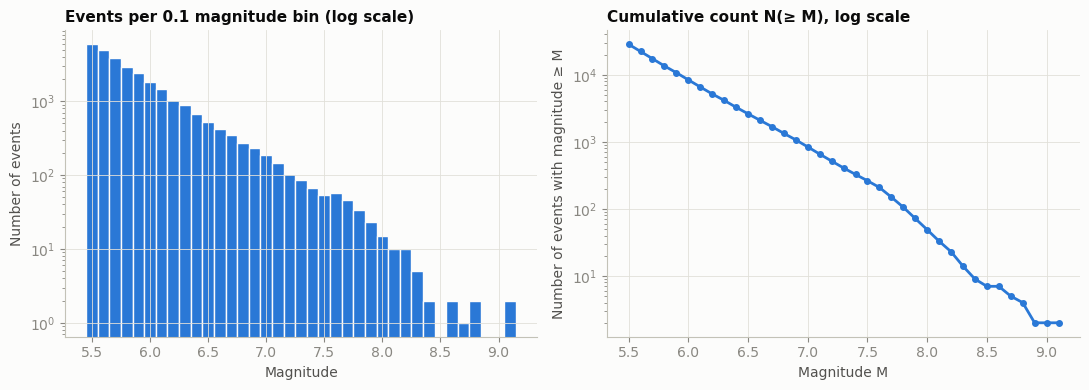

In [11]:
fig, (ax_hist, ax_cum) = plt.subplots(1, 2, figsize=(11, 4))

magnitude_bins = np.arange(5.45, df["mag"].max() + 0.15, 0.1)
ax_hist.hist(df["mag"], bins=magnitude_bins, color=SERIES[0], edgecolor=SURFACE, linewidth=1)
ax_hist.set_yscale("log")
ax_hist.set_title("Events per 0.1 magnitude bin (log scale)")
ax_hist.set_xlabel("Magnitude")
ax_hist.set_ylabel("Number of events")

magnitude_grid = np.round(np.arange(5.5, df["mag"].max() + 0.05, 0.1), 1)
cumulative_counts = [(df["mag"] >= m).sum() for m in magnitude_grid]
ax_cum.plot(magnitude_grid, cumulative_counts, color=SERIES[0], marker="o", markersize=4)
ax_cum.set_yscale("log")
ax_cum.set_title("Cumulative count N(≥ M), log scale")
ax_cum.set_xlabel("Magnitude M")
ax_cum.set_ylabel("Number of events with magnitude ≥ M")

fig.tight_layout()
save_figure(fig, "fig1_magnitude_distribution.png")
plt.show()

**Interpretation.** Magnitude is right-skewed (skew 1.92): large events are much rarer than events near the catalogue threshold. The logarithmic count axis makes this tail visible.


### Depth distribution
We compare shallow (<70 km), intermediate (70–<300 km) and deep (≥300 km) events. Depth helps describe the catalogue, but is not itself a property-loss model.


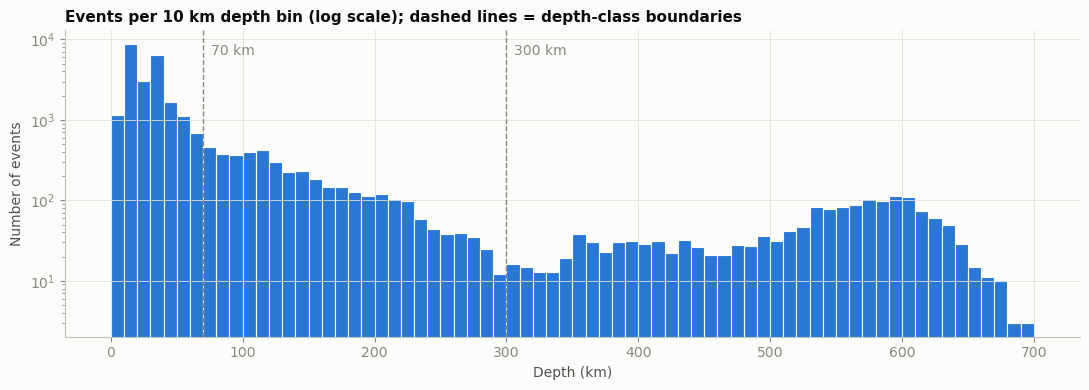

              events  share  fixed_depth_share  median_mag
depth_class                                               
shallow        22858  0.800                0.4         5.7
intermediate    4070  0.143                0.0         5.7
deep            1629  0.057                0.0         5.8


In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(df["depth"], bins=np.arange(0, 710, 10), color=SERIES[0], edgecolor=SURFACE, linewidth=0.8)
ax.set_yscale("log")
for boundary in [70, 300]:
    ax.axvline(boundary, color=INK_MUTED, linewidth=1, linestyle="--")
    ax.text(boundary + 6, ax.get_ylim()[1] * 0.5, f"{boundary} km", color=INK_MUTED)
ax.set_title("Events per 10 km depth bin (log scale); dashed lines = depth-class boundaries")
ax.set_xlabel("Depth (km)")
ax.set_ylabel("Number of events")
fig.tight_layout()
save_figure(fig, "fig2_depth_distribution.png")
plt.show()

depth_table = df.groupby("depth_class", observed=True).agg(
    events=("id", "size"), share=("id", lambda s: len(s) / len(df)),
    fixed_depth_share=("depth_fixed", "mean"), median_mag=("mag", "median"))
print(depth_table.round(3).to_string())

**Interpretation.** The current output has 22,858 shallow events out of 28,557 (about 80%). Peaks around 10 km and 33 km may partly reflect assigned depths. Those reported values fall in the shallow class, but uncertainty in true depth remains.


### Activity over time
We plot annual counts to examine variation and possible changes in recording. Both panels use the catalogue threshold or the final target threshold explicitly.


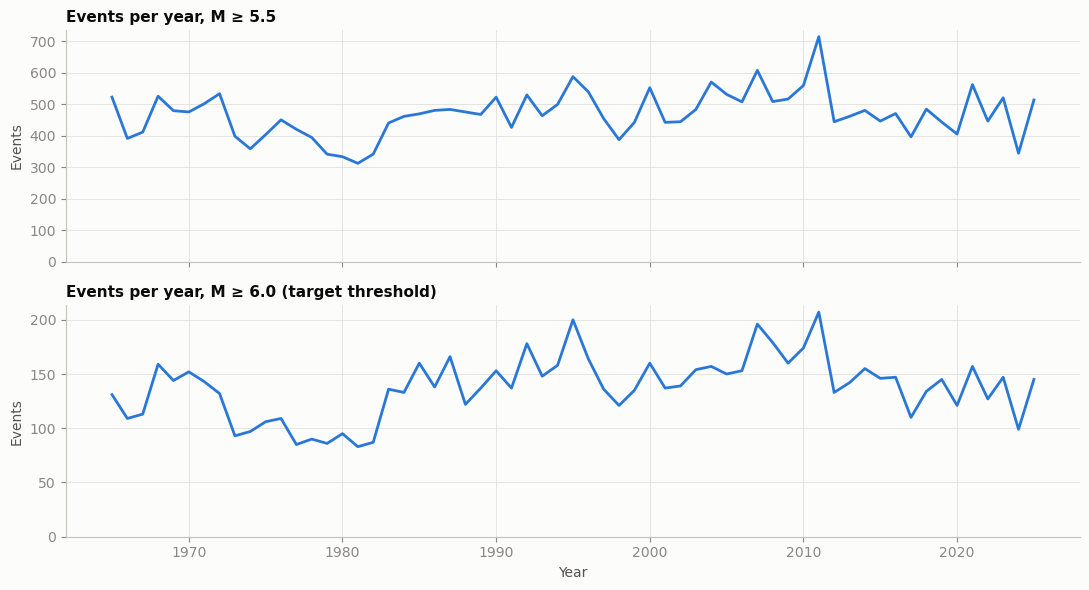

Mean events per year (M >= 5.5): 468
Mean events per year (M >= 6.0): 138


In [13]:
events_per_year = df.groupby("year").size()
strong_per_year = df[df["mag"] >= 6.0].groupby("year").size().reindex(events_per_year.index, fill_value=0)

fig, (ax_all, ax_strong) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax_all.plot(events_per_year.index, events_per_year.values, color=SERIES[0])
ax_all.set_title("Events per year, M ≥ 5.5")
ax_all.set_ylabel("Events")
ax_all.set_ylim(bottom=0)

ax_strong.plot(strong_per_year.index, strong_per_year.values, color=SERIES[0])
ax_strong.set_title("Events per year, M ≥ 6.0 (target threshold)")
ax_strong.set_ylabel("Events")
ax_strong.set_xlabel("Year")
ax_strong.set_ylim(bottom=0)

fig.tight_layout()
save_figure(fig, "fig3_events_per_year.png")
plt.show()

print(f"Mean events per year (M >= 5.5): {events_per_year.mean():.0f}")
print(f"Mean events per year (M >= 6.0): {strong_per_year.mean():.0f}")

**Interpretation.** Year-to-year differences can arise from seismic sequences and changes in measurement or catalogue practices. The plot alone does not attribute a spike to a particular earthquake or establish a long-term trend. Compare periods cautiously.


### Magnitude scales over time
We compare magnitude-family shares to assess measurement comparability across the training and evaluation periods.


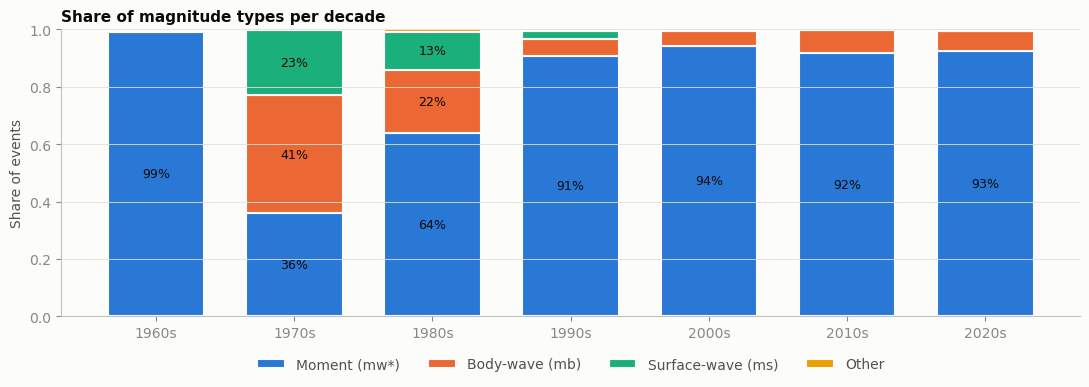

In [14]:
family_order = ["moment", "body_wave", "surface_wave", "other"]
family_labels = {"moment": "Moment (mw*)", "body_wave": "Body-wave (mb)",
                 "surface_wave": "Surface-wave (ms)", "other": "Other"}
decade = (df["year"] // 10 * 10).astype(str) + "s"
family_share = pd.crosstab(decade, df["mag_family"], normalize="index")[family_order]

fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(family_share))
for color, family in zip(SERIES, family_order):
    values = family_share[family].values
    ax.bar(family_share.index, values, bottom=bottom, color=color,
           edgecolor=SURFACE, linewidth=1.5, label=family_labels[family], width=0.7)
    for x, (value, base) in enumerate(zip(values, bottom)):
        if value >= 0.08:
            ax.text(x, base + value / 2, f"{value:.0%}", ha="center", va="center",
                    color=INK_PRIMARY, fontsize=9)
    bottom += values
ax.set_title("Share of magnitude types per decade")
ax.set_ylabel("Share of events")
ax.set_ylim(0, 1)
ax.grid(axis="x", visible=False)
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
save_figure(fig, "fig4_magnitude_types.png")
plt.show()

**Interpretation.** Magnitude-family composition changes across decades, limiting direct comparison of older and newer records. Grouping the scales identifies this issue but does not convert measurements to a common scale.


### Where recorded earthquakes occur
We map epicentres by depth. Plate boundaries provide geographical context; they are not used as predictors.


In [15]:
fig, ax = plt.subplots(figsize=(12, 6))
for depth_class in ["shallow", "intermediate", "deep"]:  # deep last so it stays visible
    subset = df[df["depth_class"] == depth_class]
    ax.scatter(subset["longitude"], subset["latitude"], s=(subset["mag"] - 5) ** 2.5 * 3,
               color=DEPTH_COLORS[depth_class], alpha=0.6, linewidths=0,
               label=f"{depth_class.capitalize()} ({len(subset):,})")
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_aspect("equal")
ax.set_xticks(range(-180, 181, 60))
ax.set_yticks(range(-90, 91, 30))
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Epicentres 1965–2025, M ≥ 5.5 (marker size = magnitude)")
legend = ax.legend(title="Depth class", loc="lower left")
legend_handles = getattr(legend, "legend_handles", None) or legend.legendHandles
for handle in legend_handles:  # same marker size for every class in the legend
    handle.set_sizes([40])
    handle.set_alpha(1)
fig.tight_layout()
save_figure(fig, "fig5_world_map.png")
plt.close(fig)  # Retain the saved figure; show the boundary-context map below.

**Interpretation.** The regenerated map shows strong geographical clustering, including around the Pacific. This motivates a regional analysis. Marker area is a nonlinear visual encoding of magnitude, not proportional released energy or damage.


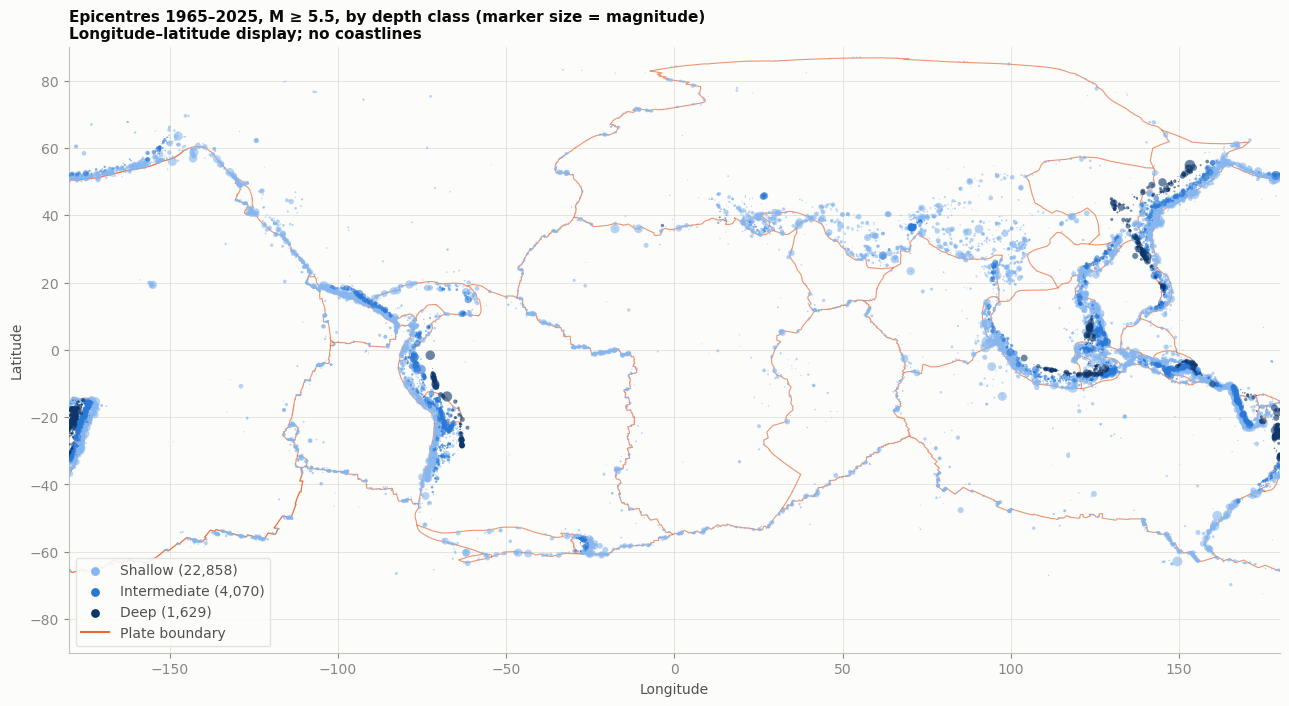

In [16]:
import json
import urllib.request

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
except ImportError:
    ccrs = None

PLATE_BOUNDARIES_URL = ("https://raw.githubusercontent.com/fraxen/tectonicplates/"
                        "master/GeoJSON/PB2002_boundaries.json")
PLATE_BOUNDARIES_FILE = Path("data/external/plate_boundaries_pb2002.json")
LAND_COLOR = "#ecebe6"
COAST_COLOR = "#b4b2a9"
PLATE_COLOR = "#eb6834"


def load_plate_boundaries(url: str = PLATE_BOUNDARIES_URL,
                          cache_file: Path = PLATE_BOUNDARIES_FILE) -> list:
    """Load tectonic plate boundary lines (Bird, 2003), downloading them once.

    Args:
        url: Location of the PB2002 plate boundary GeoJSON file.
        cache_file: Local copy, so the file is only downloaded once.

    Returns:
        List of (longitudes, latitudes) tuples, one per boundary segment.
        Empty list if the file cannot be downloaded.
    """
    try:
        if not cache_file.exists():
            raise FileNotFoundError("Supply the plate-boundary file locally; no automatic download.")
        features = json.loads(cache_file.read_text())["features"]
    except (OSError, ValueError, KeyError) as error:
        print("Plate boundaries unavailable; map is drawn without them.")
        return []
    segments = []
    for feature in features:
        coordinates = np.array(feature["geometry"]["coordinates"])
        segments.append((coordinates[:, 0], coordinates[:, 1]))
    return segments


def draw_base_map(ax) -> None:
    """Draw land, coastlines and a light graticule on a cartopy axis.

    Args:
        ax: Matplotlib axis created with a cartopy projection.
    """
    ax.set_global()
    ax.spines["geo"].set_edgecolor(AXIS)
    ax.add_feature(cfeature.LAND, facecolor=LAND_COLOR, edgecolor="none", zorder=0)
    ax.coastlines(resolution="110m", color=COAST_COLOR, linewidth=0.5, zorder=1)
    gridlines = ax.gridlines(color=GRID, linewidth=0.5, draw_labels=False, zorder=1)
    gridlines.xlocator = plt.FixedLocator(range(-180, 181, 60))
    gridlines.ylocator = plt.FixedLocator(range(-60, 61, 30))


# Centre on the Pacific so the Ring of Fire is not split at the map edge
if ccrs is not None:
    projection = ccrs.Robinson(central_longitude=150)
    fig, ax = plt.subplots(figsize=(13, 7), subplot_kw={"projection": projection})
    draw_base_map(ax)
else:
    fig, ax = plt.subplots(figsize=(13, 7))
    ax.set(xlim=(-180, 180), ylim=(-90, 90), xlabel="Longitude", ylabel="Latitude")
    ax.set_aspect("equal")

for longitudes, latitudes in load_plate_boundaries():
    if ccrs is None:
        # Break date-line crossings rather than drawing a line across the whole map.
        longitudes, latitudes = np.asarray(longitudes, dtype=float).copy(), np.asarray(latitudes, dtype=float).copy()
        jumps = np.flatnonzero(np.abs(np.diff(longitudes)) > 180) + 1
        longitudes = np.insert(longitudes, jumps, np.nan)
        latitudes = np.insert(latitudes, jumps, np.nan)
    transform = {"transform": ccrs.Geodetic()} if ccrs is not None else {}
    ax.plot(longitudes, latitudes, color=PLATE_COLOR, linewidth=0.8, alpha=0.7, zorder=2, **transform)

for depth_class in ["shallow", "intermediate", "deep"]:  # deep last so it stays visible
    subset = df[df["depth_class"] == depth_class]
    ax.scatter(subset["longitude"], subset["latitude"], s=(subset["mag"] - 5) ** 2.5 * 3,
               color=DEPTH_COLORS[depth_class], alpha=0.6, linewidths=0,
               zorder=3, **({"transform": ccrs.PlateCarree()} if ccrs is not None else {}),
               label=f"{depth_class.capitalize()} ({len(subset):,})")

ax.plot([], [], color=PLATE_COLOR, linewidth=1.5, label="Plate boundary")  # legend entry only
legend = ax.legend(loc="lower left", frameon=True, framealpha=0.9, edgecolor=GRID, facecolor=SURFACE)
legend_handles = getattr(legend, "legend_handles", None) or legend.legendHandles
for handle in legend_handles:  # same marker size for every depth class in the legend
    if hasattr(handle, "set_sizes"):
        handle.set_sizes([40])
        handle.set_alpha(1)
ax.set_title("Epicentres 1965–2025, M ≥ 5.5, by depth class (marker size = magnitude)"
             + ("\nLongitude–latitude display; no coastlines" if ccrs is None else ""))
fig.tight_layout()
save_figure(fig, "Real_world_map.png")
plt.show()

### Relationships between variables
Pearson correlation summarizes pairwise linear association. Boxplots compare magnitude distributions across reported depth classes.


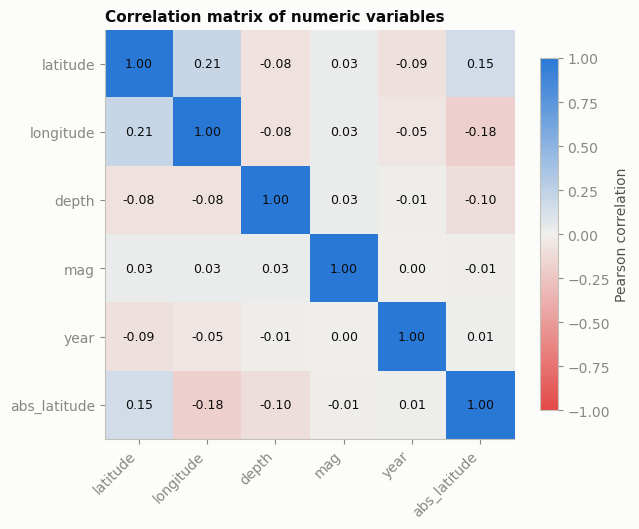

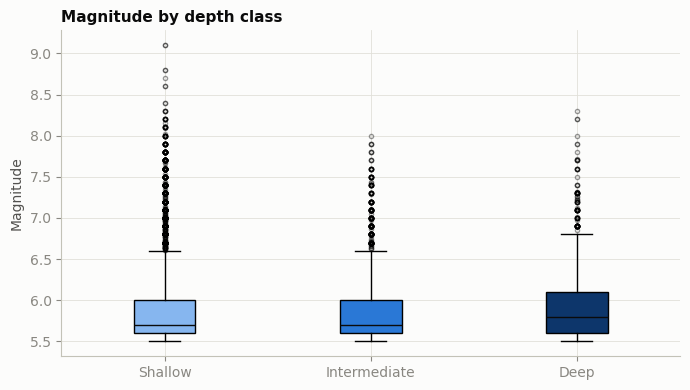

In [17]:
numeric = df[["latitude", "longitude", "depth", "mag", "year"]].copy()
numeric["abs_latitude"] = numeric["latitude"].abs()
correlation = numeric.corr().round(2)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(correlation, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlation)), correlation.columns)
ax.grid(False)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(j, i, f"{correlation.iloc[i, j]:.2f}", ha="center", va="center",
                color=INK_PRIMARY, fontsize=9)
fig.colorbar(image, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation matrix of numeric variables")
fig.tight_layout()
save_figure(fig, "fig6_correlation.png")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
groups = [df.loc[df["depth_class"] == c, "mag"] for c in ["shallow", "intermediate", "deep"]]
box = ax.boxplot(groups, patch_artist=True,
                 medianprops={"color": INK_PRIMARY}, flierprops={"markersize": 3, "alpha": 0.4})
ax.set_xticks([1, 2, 3], ["Shallow", "Intermediate", "Deep"])
for patch, color in zip(box["boxes"], DEPTH_COLORS.values()):
    patch.set_facecolor(color)
ax.set_title("Magnitude by depth class")
ax.set_ylabel("Magnitude")
fig.tight_layout()
save_figure(fig, "fig7_magnitude_by_depth.png")
plt.show()

**Interpretation.** Correlations in this selected event catalogue do not establish causation or rule out nonlinear relationships. They do not show that earthquake magnitude is generally unpredictable. The research target is annual regional occurrence, chosen for the stated application.


## 5. Regional aggregation and target definition
We compare candidate magnitude thresholds to understand outcome rarity. This exploratory preview includes all 759 cells observed through 2025; the final modelling population uses only 722 cells with an event by 2015. Rates from these two populations must not be conflated.


In [18]:
GRID_SIZE_DEGREES = 5
TARGET_YEARS = range(1975, 2026)  # first 10 years are reserved for history features

df["cell_lat"] = np.floor(df["latitude"].astype(float).clip(upper=np.nextafter(90.0, -np.inf)) / GRID_SIZE_DEGREES) * GRID_SIZE_DEGREES
df["cell_lon"] = np.floor(((df["longitude"] + 180) % 360 - 180) / GRID_SIZE_DEGREES) * GRID_SIZE_DEGREES
df["cell_id"] = df["cell_lat"].astype(int).astype(str) + "_" + df["cell_lon"].astype(int).astype(str)

active_cells = df["cell_id"].unique()
region_years = pd.MultiIndex.from_product([active_cells, TARGET_YEARS], names=["cell_id", "year"])
print(f"Active {GRID_SIZE_DEGREES}°x{GRID_SIZE_DEGREES}° cells: {len(active_cells)}")
print(f"Region-years in target period: {len(region_years):,}\n")

rows = []
for threshold in [6.0, 6.5, 7.0]:
    strong_counts = (df[df["mag"] >= threshold].groupby(["cell_id", "year"]).size()
                     .reindex(region_years, fill_value=0))
    rows.append({"threshold": f"M >= {threshold}", "positive_region_years": int((strong_counts > 0).sum()),
                 "positive_share": (strong_counts > 0).mean()})
base_rates = pd.DataFrame(rows)
print(base_rates.to_string(index=False, formatters={"positive_share": "{:.1%}".format}))

Active 5°x5° cells: 759
Region-years in target period: 38,709

threshold  positive_region_years positive_share
 M >= 6.0                   4026          10.4%
 M >= 6.5                   1668           4.3%
 M >= 7.0                    625           1.6%


**Decision.** The regenerated preview reports positive region-year shares of 10.4% (M ≥ 6.0), 4.3% (M ≥ 6.5) and 1.6% (M ≥ 7.0). We retain M ≥ 6.0 as the existing project target, balancing the application and available examples. Threshold choice is a substantive assumption, not evidence that this value is optimal.


### Geographical scope and limitations
A 5° cell spans about the same north–south distance everywhere, but its east–west width shrinks with latitude (approximately with the cosine of latitude). Cells therefore have unequal physical areas. A named city only identifies its containing cell; its quoted probability applies to that whole region, including offshore areas, not just the city.

The final comparison includes cells with at least one recorded M ≥ 5.5 earthquake during 1965–2015. Earlier fitting/validation subsets are further restricted to cells known by their fitting cutoff. Blank forecast cells are **outside the model population**, not established zero-risk locations. Catalogue thresholds, a short observation window and sparse events can all hide rare hazard. Fixed grid borders also separate events that may be physically close.


## 6. Feature engineering
We create a complete annual panel, including zero-event years. The target is 1 when at least one M ≥ 6.0 event occurs in the year. Predictors summarize the preceding ten years and an expanding record from 1965, always **ending before the target year**.

Recent counts describe recorded short-term activity; expanding rates retain longer history. Neither measures fault stress directly.

**Conventions:** maximum magnitude 5.0 is a placeholder for an empty M ≥ 5.5 window. A shallow share of zero can also mean no events. `years_since_strong=11` means none in the previous ten years, not an observed recurrence interval. Original depths are retained separately.


In [19]:
"""Build the region-year modelling table from the cleaned earthquake catalogue.

Each row is one 5°x5° grid cell in one year. The target says whether at least
one strong earthquake (M >= 6.0) occurred in that cell in that year. All
features describe the cell's seismic history in the ten years BEFORE the
target year, so no information from the target year leaks into the features.

Design decisions (documented for the report):
    1. Grid: 5°x5° cells (about 550 km x 550 km at the equator).
    2. Cell universe: cells with at least one event up to 2015, the end of
       the training period. Cells that only became active later are excluded,
       so choosing the cells does not use future information.
    3. Target years 1975-2025. The years 1965-1974 only supply history for
       the first target years, because every feature needs a full ten years.
    4. Time-based split: target years 1975-2015 for training, 2016-2025 for
       testing. A random split would let the models learn from the future.
    5. Count features are strongly right-skewed, so log(1 + x) versions are
       added for the regression models (log transform, Lecture 1).
    6. Long-term rates: besides the 10-year window, every row gets the average
       yearly number of events and of strong events over ALL years from 1965 up
       to the year before the target year (an expanding window). Faults with
       long recurrence times (e.g. the San Andreas system) can be quiet for a
       decade, which a 10-year window misreads as low hazard.

Usage (from a notebook in the same folder):
    from build_features import build_region_year_table
    features_df = build_region_year_table()
"""

from __future__ import annotations

from pathlib import Path

import numpy as np
import pandas as pd

CLEAN_FILE = REVISED_DATA_DIR / "earthquakes_clean.csv"
FEATURES_FILE = REVISED_DATA_DIR / "region_year_features.csv"

GRID_SIZE_DEGREES = 5
STRONG_MAGNITUDE = 6.0
HISTORY_YEARS = 10
FIRST_CATALOG_YEAR = 1965
FIRST_TARGET_YEAR = FIRST_CATALOG_YEAR + HISTORY_YEARS  # 1975
LAST_TARGET_YEAR = 2025
LAST_TRAIN_YEAR = 2015
SHALLOW_DEPTH_KM = 70
NO_EVENT_MAGNITUDE = 5.0  # placeholder max magnitude when a cell had no M >= 5.5 event

FEATURE_COLUMNS = [
    "n_events_prev10", "n_strong_prev10", "max_mag_prev10", "n_events_prev1",
    "years_since_strong", "share_shallow_prev10", "abs_lat",
    "log_events_prev10", "log_strong_prev10",
    "events_rate_longterm", "strong_rate_longterm",
    "log_events_rate_longterm", "log_strong_rate_longterm",
]
TARGET_COLUMN = "strong_quake"


def load_clean_catalog(clean_file: Path = CLEAN_FILE) -> pd.DataFrame:
    """Load the cleaned earthquake catalogue.

    Args:
        clean_file: Path to the CSV written by clean_usgs_data.py.

    Returns:
        DataFrame with the time column parsed as UTC datetimes.
    """
    catalog = pd.read_csv(clean_file)
    catalog["time"] = pd.to_datetime(catalog["time"], utc=True, format="ISO8601")
    return catalog


def assign_grid_cells(catalog: pd.DataFrame,
                      grid_size: int = GRID_SIZE_DEGREES) -> pd.DataFrame:
    """Assign every event to a square latitude-longitude grid cell.

    Args:
        catalog: Earthquake catalogue with latitude and longitude columns.
        grid_size: Cell edge length in degrees.

    Returns:
        Copy of the catalogue with cell_id, cell_lat and cell_lon columns,
        where cell_lat and cell_lon are the coordinates of the cell centre.
    """
    catalog = catalog.copy()
    # Canonical coordinates at the date line and north pole avoid off-grid cells.
    latitudes = catalog["latitude"].astype(float).clip(upper=np.nextafter(90.0, -np.inf))
    catalog["longitude"] = (catalog["longitude"] + 180) % 360 - 180
    lat_edge = np.floor(latitudes / grid_size) * grid_size
    lon_edge = np.floor(catalog["longitude"] / grid_size) * grid_size
    catalog["cell_id"] = lat_edge.astype(int).astype(str) + "_" + lon_edge.astype(int).astype(str)
    catalog["cell_lat"] = lat_edge + grid_size / 2
    catalog["cell_lon"] = lon_edge + grid_size / 2
    return catalog


def build_annual_panel(catalog: pd.DataFrame, strong_magnitude: float = STRONG_MAGNITUDE,
                       last_train_year: int = LAST_TRAIN_YEAR) -> pd.DataFrame:
    """Aggregate events to one row per cell and year, including zero-event years.

    Args:
        catalog: Catalogue with grid cells assigned (see assign_grid_cells).
        strong_magnitude: Magnitude threshold that defines a strong quake.
        last_train_year: Last year used to decide which cells are included.

    Returns:
        Panel with one row per (cell_id, year) for all included cells and all
        catalogue years, with yearly counts and the maximum magnitude.
    """
    events = catalog.assign(
        is_strong=catalog["mag"] >= strong_magnitude,
        is_shallow=catalog["depth"] < SHALLOW_DEPTH_KM,
    )
    annual = events.groupby(["cell_id", "year"]).agg(
        n_events=("id", "size"),
        n_strong=("is_strong", "sum"),
        n_shallow=("is_shallow", "sum"),
        max_mag=("mag", "max"),
    )

    # Only cells with known activity up to the end of the training period
    included_cells = events.loc[events["year"] <= last_train_year, "cell_id"].unique()
    all_years = range(int(events["year"].min()), int(events["year"].max()) + 1)
    full_index = pd.MultiIndex.from_product([included_cells, all_years],
                                            names=["cell_id", "year"])
    panel = annual.reindex(full_index).reset_index()
    count_columns = ["n_events", "n_strong", "n_shallow"]
    panel[count_columns] = panel[count_columns].fillna(0).astype(int)
    # Years without events get a placeholder below the catalogue's 5.5 threshold
    panel["max_mag"] = panel["max_mag"].fillna(NO_EVENT_MAGNITUDE)

    cell_coordinates = events.groupby("cell_id")[["cell_lat", "cell_lon"]].first()
    return panel.merge(cell_coordinates, on="cell_id", how="left")


def rolling_history(panel: pd.DataFrame, column: str, window: int, how: str) -> pd.Series:
    """Aggregate a column over the previous `window` years of each cell.

    The current year is excluded (shift by one year), so the result only
    uses information that was available before the target year.

    Args:
        panel: Annual panel sorted by cell_id and year.
        column: Column to aggregate.
        window: Number of previous years to include.
        how: Aggregation, either "sum" or "max".

    Returns:
        Series aligned with the panel; NaN where fewer than `window` years exist.
    """
    return panel.groupby("cell_id")[column].transform(
        lambda values: getattr(values.shift(1).rolling(window, min_periods=window), how)()
    )


def long_term_rate(panel: pd.DataFrame, column: str,
                   first_year: int = FIRST_CATALOG_YEAR) -> pd.Series:
    """Average yearly count of a column over all years before the current year.

    Uses an expanding window from the first catalogue year up to the previous
    year, so the target year itself is never included.

    Args:
        panel: Annual panel sorted by cell_id and year.
        column: Yearly count to average (e.g. "n_strong").
        first_year: First year of the catalogue.

    Returns:
        Events per year before the current year; NaN for the first year.
    """
    count_before = panel.groupby("cell_id")[column].transform(
        lambda values: values.shift(1).cumsum())
    years_before = (panel["year"] - first_year).where(panel["year"] > first_year)
    return count_before / years_before


def add_history_features(panel: pd.DataFrame, window: int = HISTORY_YEARS) -> pd.DataFrame:
    """Add all past-only features to the annual panel.

    Args:
        panel: Annual panel from build_annual_panel.
        window: Length of the history window in years.

    Returns:
        Panel with the feature columns listed in FEATURE_COLUMNS.
    """
    panel = panel.sort_values(["cell_id", "year"]).reset_index(drop=True)

    panel["n_events_prev10"] = rolling_history(panel, "n_events", window, "sum")
    panel["n_strong_prev10"] = rolling_history(panel, "n_strong", window, "sum")
    n_shallow_prev10 = rolling_history(panel, "n_shallow", window, "sum")
    panel["max_mag_prev10"] = rolling_history(panel, "max_mag", window, "max")
    panel["n_events_prev1"] = panel.groupby("cell_id")["n_events"].shift(1)

    # Years since the last strong quake, capped at window + 1 ("none in window")
    strong_year = panel["year"].where(panel["n_strong"] > 0)
    last_strong_before = strong_year.groupby(panel["cell_id"]).transform(
        lambda years: years.ffill().shift(1))
    panel["years_since_strong"] = ((panel["year"] - last_strong_before)
                                   .fillna(window + 1).clip(upper=window + 1))

    panel["share_shallow_prev10"] = (n_shallow_prev10 / panel["n_events_prev10"]).fillna(0)
    panel["abs_lat"] = panel["cell_lat"].abs()
    panel["log_events_prev10"] = np.log1p(panel["n_events_prev10"])
    panel["log_strong_prev10"] = np.log1p(panel["n_strong_prev10"])

    # Long-term rates (expanding window since 1965) for long-recurrence faults
    panel["events_rate_longterm"] = long_term_rate(panel, "n_events")
    panel["strong_rate_longterm"] = long_term_rate(panel, "n_strong")
    panel["log_events_rate_longterm"] = np.log1p(panel["events_rate_longterm"])
    panel["log_strong_rate_longterm"] = np.log1p(panel["strong_rate_longterm"])
    return panel


def build_region_year_table(clean_file: Path = CLEAN_FILE,
                            features_file: Path = FEATURES_FILE,
                            strong_magnitude: float = STRONG_MAGNITUDE,
                            verbose: bool = True) -> pd.DataFrame:
    """Run the full feature pipeline and save the modelling table.

    Args:
        clean_file: Path to the cleaned catalogue.
        features_file: Path where the modelling table is saved.
        strong_magnitude: Magnitude threshold for the target variable.
        verbose: If True, print a summary for the report.

    Returns:
        Modelling table with identifiers, features, target and split columns.
    """
    catalog = assign_grid_cells(load_clean_catalog(clean_file))
    panel = build_annual_panel(catalog, strong_magnitude)
    panel = add_history_features(panel)

    panel[TARGET_COLUMN] = (panel["n_strong"] > 0).astype(int)
    panel = panel[panel["year"].between(FIRST_TARGET_YEAR, LAST_TARGET_YEAR)].copy()
    panel["split"] = np.where(panel["year"] <= LAST_TRAIN_YEAR, "train", "test")

    # Drop same-year columns so they cannot accidentally be used as features
    first_observed = catalog.groupby("cell_id")["year"].min()
    panel["first_observed_year"] = panel["cell_id"].map(first_observed)
    output_columns = (["cell_id", "cell_lat", "cell_lon", "year", "split", "first_observed_year"]
                      + FEATURE_COLUMNS + [TARGET_COLUMN])
    table = panel[output_columns].reset_index(drop=True)
    assert not table.duplicated(["cell_id", "year"]).any()
    assert not table[FEATURE_COLUMNS].isna().any().any()
    assert table[TARGET_COLUMN].isin([0, 1]).all()

    features_file.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(features_file, index=False)

    if verbose:
        print("--- Region-year table ---")
        print(f"Grid: {GRID_SIZE_DEGREES}°x{GRID_SIZE_DEGREES}°, "
              f"target: at least one M >= {strong_magnitude} quake in the year")
        print(f"Cells: {table['cell_id'].nunique()}, rows: {len(table):,}, "
              f"missing values: {table[FEATURE_COLUMNS].isna().sum().sum()}")
        print("\nRows and positive share per split:")
        print(table.groupby("split")[TARGET_COLUMN].agg(rows="size", positives="sum",
                                                        positive_share="mean")
              .round(3).to_string())


    return table


In [20]:
features_df = build_region_year_table()


--- Region-year table ---
Grid: 5°x5°, target: at least one M >= 6.0 quake in the year
Cells: 722, rows: 36,822, missing values: 0

Rows and positive share per split:
        rows  positives  positive_share
split                                  
test    7220        763           0.106
train  29602       3249           0.110


### Check historical boundaries
We alter target-year aggregates and confirm that predictors for that year remain unchanged. This checks exclusion of same-year outcomes; it does not establish that retrospectively revised catalogue information was available at historical forecast dates.


In [21]:
def check_history_boundaries(check_year=2016):
    catalog = assign_grid_cells(load_clean_catalog())
    panel = build_annual_panel(catalog)
    before = add_history_features(panel.copy())
    altered = panel.copy()
    target_rows = altered["year"].eq(check_year)
    altered.loc[target_rows, ["n_events", "n_strong", "n_shallow", "max_mag"]] = [999, 999, 999, 9.9]
    after = add_history_features(altered)
    keys = ["cell_id", "year"]
    left = before.loc[before["year"].eq(check_year), keys + FEATURE_COLUMNS].set_index(keys).sort_index()
    right = after.loc[after["year"].eq(check_year), keys + FEATURE_COLUMNS].set_index(keys).sort_index()
    pd.testing.assert_frame_equal(left, right)

check_history_boundaries()


## 7. Chronological evaluation design
**1975–2005:** fit scaling and select regression predictors using cells already observed by 2005. **2006–2015:** tune classification cutoffs and CART size without fitting regression coefficients or selecting predictors on these outcomes. Freeze selected predictors, then refit on **1975–2015** before evaluating **2016–2025**.

Predictors update annually: a 2020 estimate can use 2016–2019 observations, never 2020 or later. Fixed-fit model coefficients remain frozen after 2015. This is not a ten-year forecast issued in 2015. A later section checks two rolling origins; both evaluations remain exploratory because these years influenced development.


## 8. Baselines and predictive models
Logistic and cloglog regressions map predictors to probabilities using different curve shapes. Random Forest averages many trees; CART provides a single readable rule tree.

The **constant baseline** assigns the fitting-period positive share everywhere. Its classification threshold labels every row negative, but its probability is not zero. The **historical baseline** estimates each cell's fraction of previous positive years, smoothed toward pooled earlier history:

`(past positive years + 10 × pooled past frequency) / (past years + 10)`

The ten pseudo-years are a fixed stabilization assumption. All terms exclude the target year. This baseline tests whether complexity adds value beyond persistent regional activity.

**Classification:** precision is the positive share among flagged rows; recall is the share of positives caught; F1 balances both. Cutoffs maximize validation F1 and do not affect probability-based pricing. Always predicting no event gives 89.43% accuracy but zero recall, illustrating why accuracy alone misleads.

**Regression selection:** AIC/BIC balance fit against parameter count. Compare them only on the same outcome and rows: selection scores use 1975–2005, whereas final-refit scores use 1975–2015. Coefficients describe associations, not causes; dependent data and feature selection limit p-value interpretation. Values printed as 0.0000 are rounded.


In [22]:
"""Fit Logistic, Cloglog and Random Forest; compare constant and historical-rate baselines.

Regression feature selection and its scaling use only internal fitting years
1975-2005 and cells observed by 2005. Validation years 2006-2015 choose
classification cutoffs. Selected predictors are frozen before refitting on
1975-2015; features update annually when evaluating 2016-2025.

These evaluation years influenced prior development, so this is exploratory,
not an untouched holdout. AUC measures ranking; Brier score measures mean
squared probability error and does not establish calibration by itself.
Cloglog coefficients can describe relative Poisson-equivalent rates under
that interpretation, not actual insured loss ratios or causal effects.

No class weighting is applied because probabilities feed the pricing example.
An absence of weighting does not itself guarantee calibration. Functions are
defined within this notebook; no separate train_models.py file is required.
"""

from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, brier_score_loss, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)

FEATURES_FILE = REVISED_DATA_DIR / "region_year_features.csv"
PREDICTIONS_FILE = REVISED_DATA_DIR / "test_predictions.csv"
FIG_DIR = REVISED_FIG_DIR

TARGET_COLUMN = "strong_quake"
LAST_SUBTRAIN_YEAR = 2005  # fit on 1975-2005, tune cut-offs on 2006-2015
RANDOM_STATE = 42

GLM_FEATURES = [
    "log_events_prev10", "log_strong_prev10", "max_mag_prev10", "log_events_prev1",
    "years_since_strong", "share_shallow_prev10", "abs_lat",
    "log_events_rate_longterm", "log_strong_rate_longterm",
]
FOREST_FEATURES = [
    "n_events_prev10", "n_strong_prev10", "max_mag_prev10", "n_events_prev1",
    "years_since_strong", "share_shallow_prev10", "abs_lat",
    "events_rate_longterm", "strong_rate_longterm",
]
MODEL_COLORS = {"Logistic": "#2a78d6", "Cloglog": "#eb6834", "Random forest": "#1baf7a",
                "Historical rate": "#8a55a2"}


# ---------------------------------------------------------------- data

def load_modelling_table(features_file: Path = FEATURES_FILE) -> pd.DataFrame:
    """Load the region-year table and add the log of last year's event count.

    Args:
        features_file: Path to the CSV written by build_features.py.

    Returns:
        Modelling table with the extra column log_events_prev1.
    """
    table = pd.read_csv(features_file)
    table["log_events_prev1"] = np.log1p(table["n_events_prev1"])
    return table


def standardize(train: pd.DataFrame, others: list[pd.DataFrame],
                columns: list[str]) -> tuple[pd.DataFrame, list[pd.DataFrame]]:
    """Standardise columns with the training mean and standard deviation.

    Using training statistics only prevents information from the validation
    or test data leaking into the model.

    Args:
        train: Training rows.
        others: Further DataFrames (validation, test) to transform the same way.
        columns: Columns to standardise.

    Returns:
        Standardised copies of the training frame and of each other frame.
    """
    means, stds = train[columns].mean(), train[columns].std().replace(0, 1)
    scale = lambda frame: (frame[columns] - means) / stds
    return scale(train), [scale(frame) for frame in others]


# ---------------------------------------------------------------- regression models

def fit_glm(features: pd.DataFrame, target: pd.Series, link: str):
    """Fit a binomial GLM with a logit or complementary log-log link.

    Args:
        features: Standardised feature matrix (without intercept).
        target: Binary target (0/1).
        link: "logit" or "cloglog".

    Returns:
        Fitted statsmodels GLM results object.
    """
    link_function = sm.families.links.Logit() if link == "logit" else sm.families.links.CLogLog()
    family = sm.families.Binomial(link=link_function)
    return sm.GLM(target, sm.add_constant(features, has_constant="add"), family=family).fit()


def information_criteria(glm_results) -> dict:
    """Compute AIC and BIC exactly as defined in the lecture.

    AIC = -2 ln(L) + 2k and BIC = -2 ln(L) + k ln(N), with L the maximised
    likelihood, k the number of parameters (incl. intercept), N the sample size.

    Args:
        glm_results: Fitted statsmodels GLM results.

    Returns:
        Dictionary with log_likelihood, k, aic and bic.
    """
    log_likelihood = glm_results.llf
    n_parameters = len(glm_results.params)
    n_samples = glm_results.nobs
    return {
        "log_likelihood": log_likelihood,
        "k": n_parameters,
        "aic": -2 * log_likelihood + 2 * n_parameters,
        "bic": -2 * log_likelihood + n_parameters * np.log(n_samples),
    }


def backward_elimination(features: pd.DataFrame, target: pd.Series, link: str,
                         criterion: str = "aic") -> list[str]:
    """Remove features one at a time as long as the criterion improves.

    Args:
        features: Standardised feature matrix with all candidate features.
        target: Binary target.
        link: "logit" or "cloglog".
        criterion: "aic" or "bic".

    Returns:
        List of selected feature names.
    """
    selected = list(features.columns)
    best_score = information_criteria(fit_glm(features[selected], target, link))[criterion]
    while len(selected) > 1:
        scores = {
            feature: information_criteria(
                fit_glm(features[[f for f in selected if f != feature]], target, link))[criterion]
            for feature in selected
        }
        feature_to_drop = min(scores, key=scores.get)
        if scores[feature_to_drop] >= best_score:
            break
        best_score = scores[feature_to_drop]
        selected.remove(feature_to_drop)
    return selected


def coefficient_table(glm_results, link: str) -> pd.DataFrame:
    """Summarise GLM coefficients with an interpretable effect size.

    For the logit link, exp(coefficient) is an odds ratio; for the cloglog
    link it is a rate ratio (multiplicative change in the yearly rate of
    strong quakes). Both are per one standard deviation of the feature.

    Args:
        glm_results: Fitted statsmodels GLM results.
        link: "logit" or "cloglog".

    Returns:
        DataFrame with coefficient, p-value and effect ratio per feature.
    """
    ratio_name = "odds_ratio" if link == "logit" else "rate_ratio"
    table = pd.DataFrame({
        "coefficient": glm_results.params,
        "p_value": glm_results.pvalues,
        ratio_name: np.exp(glm_results.params),
    })
    return table.drop(index="const").round(4)


# ---------------------------------------------------------------- random forest

def fit_random_forest(features: pd.DataFrame, target: pd.Series) -> RandomForestClassifier:
    """Fit a random forest classifier.

    min_samples_leaf keeps leaves large enough for smooth probabilities and
    limits overfitting (bias-variance tradeoff).

    Args:
        features: Raw (unscaled) feature matrix; trees do not need scaling.
        target: Binary target.

    Returns:
        Fitted RandomForestClassifier.
    """
    forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=50, max_features="sqrt",
                                    random_state=RANDOM_STATE, n_jobs=-1)
    return forest.fit(features, target)


# ---------------------------------------------------------------- evaluation

def best_f1_threshold(target: pd.Series, probabilities: np.ndarray) -> float:
    """Find the probability cut-off that maximises F1.

    Args:
        target: True binary labels.
        probabilities: Predicted probabilities of the positive class.

    Returns:
        Cut-off between 0.01 and 0.90 with the highest F1-score.
    """
    candidates = np.arange(0.01, 0.91, 0.01)
    scores = [f1_score(target, probabilities >= cut_off, zero_division=0) for cut_off in candidates]
    return float(candidates[int(np.argmax(scores))])


def evaluate_predictions(target: pd.Series, probabilities: np.ndarray, threshold: float) -> dict:
    """Compute all evaluation measures from the lecture plus ROC-AUC and Brier.

    Args:
        target: True binary labels.
        probabilities: Predicted probabilities of the positive class.
        threshold: Probability cut-off for predicting a strong quake.

    Returns:
        Dictionary of metrics and confusion-matrix counts.
    """
    predicted = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(target, predicted, labels=[0, 1]).ravel()
    has_both_classes = target.nunique() == 2
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(target, predicted),
        "precision": precision_score(target, predicted, zero_division=0),
        "recall": recall_score(target, predicted, zero_division=0),
        "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
        "f1": f1_score(target, predicted, zero_division=0),
        "roc_auc": roc_auc_score(target, probabilities) if has_both_classes else np.nan,
        "brier": brier_score_loss(target, probabilities),
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
    }


# ---------------------------------------------------------------- plots

def plot_roc_curves(target: pd.Series, probabilities: dict, file_name: str = "fig8_roc_curves.png"):
    """Plot ROC curves of all models on the test data.

    Args:
        target: True binary labels of the test data.
        probabilities: Mapping from model name to predicted probabilities.
        file_name: File name for the saved figure.
    """
    fig, ax = plt.subplots(figsize=(6, 6))
    for name, model_probabilities in probabilities.items():
        false_positive_rate, true_positive_rate, _ = roc_curve(target, model_probabilities)
        auc = roc_auc_score(target, model_probabilities)
        ax.plot(false_positive_rate, true_positive_rate, color=MODEL_COLORS[name],
                label=f"{name} (AUC = {auc:.3f})")
    ax.plot([0, 1], [0, 1], color="#898781", linestyle="--", linewidth=1, label="Random (AUC = 0.5)")
    ax.set_xlabel("False positive rate (1 - specificity)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title("ROC curves: exploratory annual-updating evaluation 2016-2025")
    ax.legend(loc="lower right")
    ax.set_aspect("equal")
    fig.tight_layout()
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / file_name, dpi=200, bbox_inches="tight")
    plt.show()


def plot_confusion_matrices(metrics: pd.DataFrame,
                            file_name: str = "fig9_confusion_matrices.png"):
    """Plot one confusion matrix per model, laid out as in the lecture.

    Args:
        metrics: Test metrics per model (rows) with TP, FP, TN and FN columns.
        file_name: File name for the saved figure.
    """
    models = [name for name in MODEL_COLORS if name in metrics.index]
    fig, axes = plt.subplots(1, len(models), figsize=(4.2 * len(models), 3.8))
    for ax, name in zip(np.atleast_1d(axes), models):
        row = metrics.loc[name]
        matrix = np.array([[row["TP"], row["FN"]], [row["FP"], row["TN"]]], dtype=int)
        ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max() * 1.6)
        labels = [["TP", "FN"], ["FP", "TN"]]
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{labels[i][j]}\n{matrix[i, j]:,}", ha="center", va="center",
                        color="#0b0b0b", fontsize=10)
        ax.set_xticks([0, 1], ["Predicted strong", "Predicted none"])
        ax.set_yticks([0, 1], ["Actual strong", "Actual none"])
        ax.grid(False)
        ax.set_title(f"{name} (cut-off {row['threshold']:.2f})")
    fig.tight_layout()
    fig.savefig(FIG_DIR / file_name, dpi=200, bbox_inches="tight")
    plt.show()


def plot_feature_importance(forest: RandomForestClassifier, feature_names: list[str],
                            file_name: str = "fig10_feature_importance.png"):
    """Plot random-forest feature importances (mean impurity decrease).

    Args:
        forest: Fitted random forest.
        feature_names: Names of the features in training order.
        file_name: File name for the saved figure.
    """
    importance = pd.Series(forest.feature_importances_, index=feature_names).sort_values()
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(importance.index, importance.values, color=MODEL_COLORS["Random forest"])
    ax.set_xlabel("Mean decrease in Gini impurity")
    ax.set_title("Random forest feature importance")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / file_name, dpi=200, bbox_inches="tight")
    plt.show()


# ---------------------------------------------------------------- pipeline

def run_modelling(features_file: Path = FEATURES_FILE, make_plots: bool = True) -> dict:
    """Run feature selection, tuning, training and evaluation for all models.

    Args:
        features_file: Path to the region-year table.
        make_plots: If True, draw and save the evaluation figures.

    Returns:
        Dictionary with the comparison tables, coefficient tables, fitted
        models and the test predictions.
    """
    table = load_modelling_table(features_file)
    train = table[table["split"] == "train"]
    test = table[table["split"] == "test"]
    eligible = train["first_observed_year"].le(LAST_SUBTRAIN_YEAR)
    subtrain = train[eligible & train["year"].le(LAST_SUBTRAIN_YEAR)]
    validation = train[eligible & train["year"].gt(LAST_SUBTRAIN_YEAR)]
    assert subtrain["year"].max() < validation["year"].min() < test["year"].min()

    # 1. Freeze feature selection using only internal fitting years
    selection_scaled, _ = standardize(subtrain, [], GLM_FEATURES)
    selection_rows, selected_features = [], {}
    for link in ["logit", "cloglog"]:
        candidates = {"full": GLM_FEATURES,
                      "AIC-selected": backward_elimination(selection_scaled, subtrain[TARGET_COLUMN], link, "aic"),
                      "BIC-selected": backward_elimination(selection_scaled, subtrain[TARGET_COLUMN], link, "bic")}
        for variant, features in candidates.items():
            criteria = information_criteria(fit_glm(selection_scaled[features], subtrain[TARGET_COLUMN], link))
            selection_rows.append({"model": link, "variant": variant, **criteria,
                                   "features": ", ".join(features)})
        selected_features[link] = candidates["AIC-selected"]  # AIC targets predictive accuracy
    model_selection = pd.DataFrame(selection_rows)

    # 2. Tune cut-offs on the validation period (fit on 1975-2005 only)
    thresholds = {}
    for name, link in [("Logistic", "logit"), ("Cloglog", "cloglog")]:
        features = selected_features[link]
        sub_scaled, (val_scaled,) = standardize(subtrain, [validation], features)
        glm = fit_glm(sub_scaled, subtrain[TARGET_COLUMN], link)
        val_probabilities = glm.predict(sm.add_constant(val_scaled, has_constant="add"))
        thresholds[name] = best_f1_threshold(validation[TARGET_COLUMN], val_probabilities)
    sub_forest = fit_random_forest(subtrain[FOREST_FEATURES], subtrain[TARGET_COLUMN])
    thresholds["Random forest"] = best_f1_threshold(
        validation[TARGET_COLUMN], sub_forest.predict_proba(validation[FOREST_FEATURES])[:, 1])

    # 3. Refit on all training years and predict the test period once
    test_probabilities, fitted_models, coefficients = {}, {}, {}
    for name, link in [("Logistic", "logit"), ("Cloglog", "cloglog")]:
        features = selected_features[link]
        train_part, (test_part,) = standardize(train, [test], features)
        glm = fit_glm(train_part, train[TARGET_COLUMN], link)
        test_probabilities[name] = np.asarray(glm.predict(sm.add_constant(test_part, has_constant="add")))
        fitted_models[name] = glm
        coefficients[name] = coefficient_table(glm, link)
    forest = fit_random_forest(train[FOREST_FEATURES], train[TARGET_COLUMN])
    test_probabilities["Random forest"] = forest.predict_proba(test[FOREST_FEATURES])[:, 1]
    fitted_models["Random forest"] = forest

    # Historical baseline threshold is tuned using earlier validation rows only.
    historical_validation = historical_rate_predictions(validation)
    thresholds["Historical rate"] = best_f1_threshold(validation[TARGET_COLUMN], historical_validation)
    test_probabilities["Historical rate"] = historical_rate_predictions(test)

    # 4. Compare exploratory test-period predictions, including both baselines
    target = test[TARGET_COLUMN]
    metric_rows = {name: evaluate_predictions(target, probabilities, thresholds[name])
                   for name, probabilities in test_probabilities.items()}
    baseline_probabilities = np.full(len(test), train[TARGET_COLUMN].mean())
    metric_rows["Constant probability"] = evaluate_predictions(target, baseline_probabilities, 1.0)
    metrics = pd.DataFrame(metric_rows).T
    for name in ["Logistic", "Cloglog"]:
        criteria = information_criteria(fitted_models[name])
        metrics.loc[name, "aic"], metrics.loc[name, "bic"] = criteria["aic"], criteria["bic"]

    predictions = test[["cell_id", "cell_lat", "cell_lon", "year", TARGET_COLUMN]].copy()
    for name, probabilities in test_probabilities.items():
        predictions["p_" + name.lower().replace(" ", "_")] = probabilities
    PREDICTIONS_FILE.parent.mkdir(parents=True, exist_ok=True)
    predictions.to_csv(PREDICTIONS_FILE, index=False)
    metrics.to_csv(REVISED_DATA_DIR / "fixed_fit_metrics.csv")
    model_selection.to_csv(REVISED_DATA_DIR / "feature_selection_internal_fit.csv", index=False)
    (REVISED_DATA_DIR / "selected_features.json").write_text(json.dumps(selected_features, indent=2))

    print("=== 1. Feature selection with AIC/BIC (fitting data 1975-2005 only) ===")
    print(model_selection.round(1).to_string(index=False))
    for name in ["Logistic", "Cloglog"]:
        print(f"\n=== Coefficients: {name} (standardised features; ratio per +1 SD) ===")
        print(coefficients[name].to_string())

    if make_plots:
        plot_roc_curves(target, test_probabilities)
        plot_confusion_matrices(metrics)
        plot_feature_importance(forest, FOREST_FEATURES)

    return {"model_selection": model_selection, "metrics": metrics, "coefficients": coefficients,
            "selected_features": selected_features, "thresholds": thresholds,
            "models": fitted_models, "predictions": predictions,
            "selection_period": "1975-2005; cells known by 2005"}


=== 1. Feature selection with AIC/BIC (fitting data 1975-2005 only) ===
  model      variant  log_likelihood  k     aic     bic                                                                                                                                                                      features
  logit         full         -5206.6 10 10433.1 10512.8 log_events_prev10, log_strong_prev10, max_mag_prev10, log_events_prev1, years_since_strong, share_shallow_prev10, abs_lat, log_events_rate_longterm, log_strong_rate_longterm
  logit AIC-selected         -5206.7  8 10429.3 10493.0                                   log_events_prev10, log_strong_prev10, years_since_strong, share_shallow_prev10, abs_lat, log_events_rate_longterm, log_strong_rate_longterm
  logit BIC-selected         -5211.4  6 10434.8 10482.6                                                                      log_events_prev10, log_strong_prev10, years_since_strong, share_shallow_prev10, log_strong_rate_longterm
cloglog 

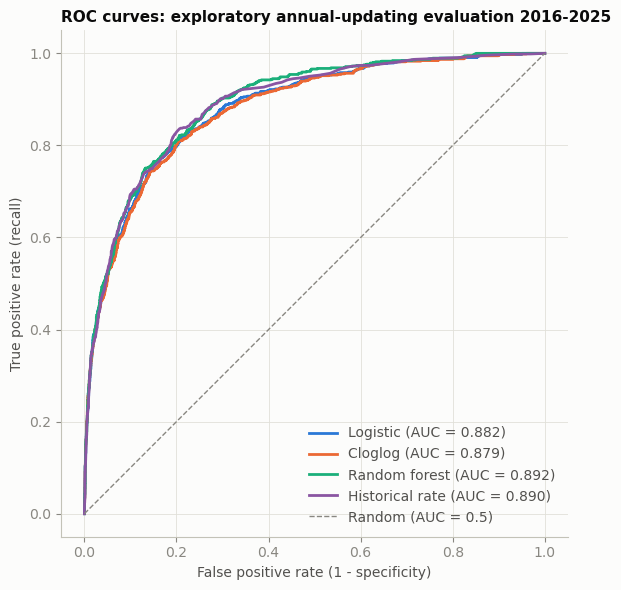

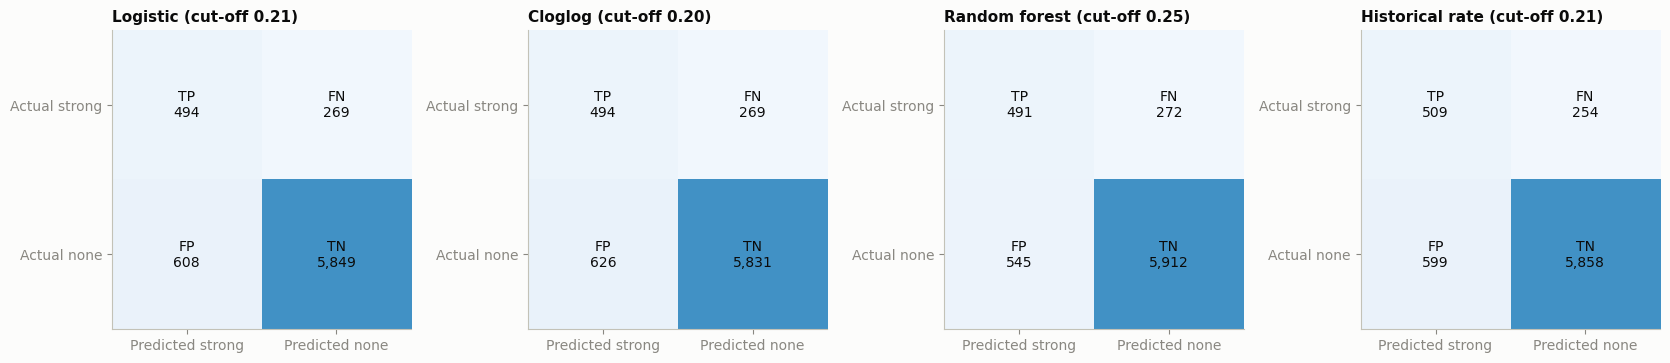

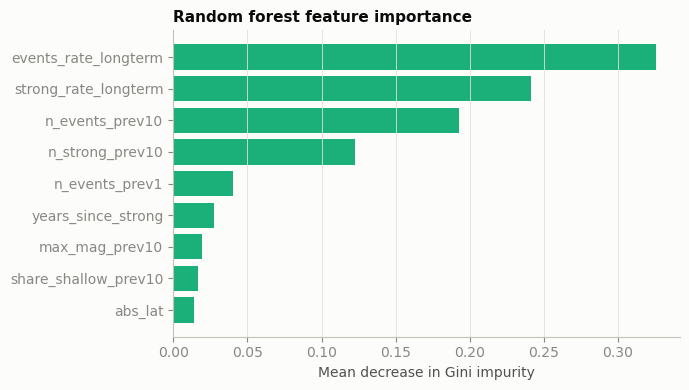

In [23]:
HISTORICAL_PRIOR_YEARS = 10.0


def smoothed_annual_probability(positive_years, observed_years, pooled_frequency,
                                prior_years=HISTORICAL_PRIOR_YEARS):
    """Blend a regional positive-year frequency with earlier pooled history."""
    positive_years = np.asarray(positive_years, dtype=float)
    observed_years = np.asarray(observed_years, dtype=float)
    pooled_frequency = np.asarray(pooled_frequency, dtype=float)
    if prior_years <= 0 or np.any(observed_years < 0):
        raise ValueError("Prior years must be positive; observed years cannot be negative.")
    if np.any(positive_years < 0) or np.any(positive_years > observed_years):
        raise ValueError("Positive years must lie between zero and observed years.")
    if np.any((pooled_frequency < 0) | (pooled_frequency > 1)):
        raise ValueError("Pooled frequencies must lie in [0, 1].")
    return (positive_years + prior_years * pooled_frequency) / (observed_years + prior_years)


def historical_rate_predictions(rows):
    """Use only pre-target years and a cell universe known at that forecast origin."""
    catalog = assign_grid_cells(load_clean_catalog())
    predictions = pd.Series(index=rows.index, dtype=float)
    # One year at a time prevents future years entering the pooled prior.
    for year, year_rows in rows.groupby("year", sort=True):
        first_seen = catalog.groupby("cell_id")["year"].min()
        known = first_seen[first_seen < year].index
        # Restrict the population to cells in the experiment, known before this year.
        known = known.intersection(rows["cell_id"].unique())
        past = catalog[catalog["year"].lt(year) & catalog["cell_id"].isin(known)]
        first_year = FIRST_CATALOG_YEAR
        n_years = int(year - first_year)
        if n_years <= 0:
            raise ValueError("A historical baseline requires at least one earlier catalogue year.")
        positive_years = (past[past["mag"].ge(STRONG_MAGNITUDE)]
                          .groupby("cell_id")["year"].nunique())
        pooled = positive_years.sum() / (len(known) * n_years) if len(known) else 0.0
        counts = year_rows["cell_id"].map(positive_years).fillna(0)
        predictions.loc[year_rows.index] = smoothed_annual_probability(counts, n_years, pooled)
    return predictions.to_numpy()


results = run_modelling()


## 9. CART risk interpretation
CART splits regions using thresholds and predicts the positive-year share of each fitted leaf. Tree size is selected on 2006–2015 validation Brier score after fitting on 1975–2005 cells already known by 2005. The chosen size is then refitted on 1975–2015 and evaluated alongside the same baselines.

A small tree may be easier to explain, but neither a high importance score nor a higher regional estimate proves causality or correctness. The historical class table compares fitted and evaluation frequencies, with sample sizes; small classes have substantial uncertainty. Rounded rules are display summaries, while prediction uses full-precision thresholds.


In [24]:
"""CART decision tree: interpretable risk classes for strong earthquakes.

CART (Classification And Regression Trees, Lecture 3) splits the regions step by
step on the feature threshold that reduces the Gini impurity most. Each leaf of
the tree is a group of region-years with similar seismic history; its predicted
probability is simply the share of those region-years that had a strong quake.
The leaves are therefore natural **risk classes**, the way insurers build rating
classes, and every class comes with a readable rule.

Workflow (same rules as the other models, the test period is touched once):
    1. Tune the tree size (max_depth, min_samples_leaf) on the validation period
       (fit 1975-2005, evaluate 2006-2015) by the Brier score, because the
       probabilities feed the premium. If two trees score equally well (to
       four decimals), take the one with fewer leaves (simpler classes).
    2. Tune the decision cut-off on the validation period by maximising F1.
    3. Refit on 1975-2015 and evaluate once on 2016-2025 next to the other models.
"""

from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

CART_FEATURES = FOREST_FEATURES  # raw features: trees do not need scaling or log transforms
CART_DEPTHS = [2, 3, 4, 5, 6]
CART_MIN_LEAF_SIZES = [50, 100, 200, 400]
MODEL_COLORS["CART"] = "#eda100"


def fit_cart(features: pd.DataFrame, target: pd.Series, max_depth: int,
             min_samples_leaf: int) -> DecisionTreeClassifier:
    """Fit a CART classification tree with the Gini criterion.

    Args:
        features: Raw feature matrix.
        target: Binary target.
        max_depth: Maximum number of splits from the root to a leaf.
        min_samples_leaf: Minimum number of region-years per leaf.

    Returns:
        Fitted DecisionTreeClassifier.
    """
    tree = DecisionTreeClassifier(criterion="gini", max_depth=max_depth,
                                  min_samples_leaf=min_samples_leaf, random_state=RANDOM_STATE)
    return tree.fit(features, target)


def tune_cart(subtrain: pd.DataFrame, validation: pd.DataFrame,
              features: list[str] = CART_FEATURES) -> tuple[dict, pd.DataFrame]:
    """Choose the tree size on the validation period.

    Args:
        subtrain: Rows used for fitting (1975-2005).
        validation: Rows used for scoring (2006-2015).
        features: Feature columns.

    Returns:
        Best parameters and the full tuning table.
    """
    rows = []
    for max_depth in CART_DEPTHS:
        for min_samples_leaf in CART_MIN_LEAF_SIZES:
            tree = fit_cart(subtrain[features], subtrain[TARGET_COLUMN], max_depth, min_samples_leaf)
            probabilities = tree.predict_proba(validation[features])[:, 1]
            rows.append({
                "max_depth": max_depth, "min_samples_leaf": min_samples_leaf,
                "leaves": tree.get_n_leaves(),
                "validation_brier": brier_score_loss(validation[TARGET_COLUMN], probabilities),
                "validation_auc": roc_auc_score(validation[TARGET_COLUMN], probabilities),
            })
    tuning = pd.DataFrame(rows)
    tuning["brier_rounded"] = tuning["validation_brier"].round(4)
    tuning = (tuning.sort_values(["brier_rounded", "leaves"]).drop(columns="brier_rounded")
              .reset_index(drop=True))
    best = tuning.iloc[0]  # best Brier score; ties go to the smaller tree
    params = {"max_depth": int(best["max_depth"]), "min_samples_leaf": int(best["min_samples_leaf"])}
    return params, tuning


def leaf_rules(tree: DecisionTreeClassifier, feature_names: list[str]) -> dict:
    """Write the path from the root to every leaf as a readable rule.

    Args:
        tree: Fitted decision tree.
        feature_names: Feature names in training order.

    Returns:
        Mapping from leaf id to a rule such as "n_events_prev10 > 3.5 and ...".
    """
    nodes = tree.tree_
    rules = {}

    def walk(node: int, bounds: dict) -> None:
        if nodes.children_left[node] == -1:  # reached a leaf
            parts = []
            for name, (low, high) in bounds.items():
                if np.isinf(low):
                    parts.append(f"{name} <= {high:.2f}")
                elif np.isinf(high):
                    parts.append(f"{name} > {low:.2f}")
                else:
                    parts.append(f"{low:.2f} < {name} <= {high:.2f}")
            rules[node] = " and ".join(parts) if parts else "all regions"
            return
        name, threshold = feature_names[nodes.feature[node]], nodes.threshold[node]
        low, high = bounds.get(name, (-np.inf, np.inf))
        walk(nodes.children_left[node], {**bounds, name: (low, min(high, threshold))})
        walk(nodes.children_right[node], {**bounds, name: (max(low, threshold), high)})

    walk(0, {})
    return rules


def describe_cart_classes(tree: DecisionTreeClassifier, fit_rows: pd.DataFrame,
                          check_rows: pd.DataFrame | None = None,
                          features: list[str] = CART_FEATURES) -> pd.DataFrame:
    """Turn the leaves of a tree into ordered risk classes C1 (lowest) to Ck.

    Args:
        tree: Fitted decision tree.
        fit_rows: Rows the tree was fitted on (gives each class's frequency).
        check_rows: Optional later rows to check how stable each class is.
        features: Feature columns.

    Returns:
        One row per class with its rule, size and strong-quake frequency.
    """
    rules = leaf_rules(tree, features)
    classes = (fit_rows.assign(leaf=tree.apply(fit_rows[features]))
               .groupby("leaf")[TARGET_COLUMN].agg(fit_region_years="size", fit_frequency="mean"))
    if check_rows is not None:
        check = (check_rows.assign(leaf=tree.apply(check_rows[features]))
                 .groupby("leaf")[TARGET_COLUMN].agg(test_region_years="size", test_frequency="mean"))
        classes = classes.join(check, how="left")
    classes = classes.sort_values("fit_frequency").reset_index()
    classes.insert(0, "risk_class", [f"C{i + 1}" for i in range(len(classes))])
    classes["rule"] = classes["leaf"].map(rules)
    return classes


def plot_cart_tree(tree: DecisionTreeClassifier, features: list[str] = CART_FEATURES,
                   file_name: str = "fig13_cart_tree.png", depth_shown: int = 2) -> None:
    """Draw the top levels of the tree (Gini, share of region-years, class mix).

    Args:
        tree: Fitted decision tree.
        features: Feature names in training order.
        file_name: File name for the saved figure.
        depth_shown: Number of levels drawn (deeper levels are summarised).
    """
    fig, ax = plt.subplots(figsize=(18, 8))
    plot_tree(tree, max_depth=depth_shown, feature_names=features, class_names=["none", "strong"],
              filled=True, proportion=True, impurity=True, rounded=True, fontsize=8, ax=ax)
    ax.set_title(f"CART tree, top {depth_shown} levels (value = share of none / strong quake)")
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / file_name, dpi=200, bbox_inches="tight")
    plt.show()


def run_cart(results: dict, make_plots: bool = True) -> dict:
    """Tune, train and evaluate the CART model and add it to the comparison.

    Args:
        results: Output of run_modelling (used for the comparison table).
        make_plots: If True, draw the tree and the ROC curves of all models.

    Returns:
        Dictionary with the tree, parameters, tuning table, cut-off, risk
        classes, the extended comparison table and the test predictions.
    """
    table = load_modelling_table()
    train = table[table["split"] == "train"]
    test = table[table["split"] == "test"]
    eligible = train["first_observed_year"].le(LAST_SUBTRAIN_YEAR)
    subtrain = train[eligible & train["year"].le(LAST_SUBTRAIN_YEAR)]
    validation = train[eligible & train["year"].gt(LAST_SUBTRAIN_YEAR)]

    params, tuning = tune_cart(subtrain, validation)
    sub_tree = fit_cart(subtrain[CART_FEATURES], subtrain[TARGET_COLUMN], **params)
    threshold = best_f1_threshold(validation[TARGET_COLUMN],
                                  sub_tree.predict_proba(validation[CART_FEATURES])[:, 1])

    tree = fit_cart(train[CART_FEATURES], train[TARGET_COLUMN], **params)
    test_probabilities = tree.predict_proba(test[CART_FEATURES])[:, 1]
    classes = describe_cart_classes(tree, train, test)

    metrics = results["metrics"].copy()
    metrics.loc["CART"] = pd.Series(evaluate_predictions(test[TARGET_COLUMN], test_probabilities, threshold))
    metrics = metrics.loc[[name for name in metrics.index if name != "Constant probability"]
                          + ["Constant probability"]]

    # Store the CART test probabilities next to the other models for the pricing backtest
    predictions = pd.read_csv(PREDICTIONS_FILE).drop(columns=["p_cart"], errors="ignore")
    cart_predictions = test[["cell_id", "year"]].assign(p_cart=test_probabilities)
    predictions = predictions.merge(cart_predictions, on=["cell_id", "year"], how="left")
    predictions.to_csv(PREDICTIONS_FILE, index=False)

    importance = pd.Series(tree.feature_importances_, index=CART_FEATURES).sort_values(ascending=False)
    print("=== CART tuning on 2006-2015 (five best by Brier score) ===")
    print(tuning.head(5).round(4).to_string(index=False))
    print(f"\nChosen: max_depth={params['max_depth']}, min_samples_leaf={params['min_samples_leaf']} "
          f"-> {tree.get_n_leaves()} risk classes; cut-off {threshold:.2f}")
    print("\n=== Feature importance (Gini decrease) ===")
    print(importance.round(3).to_string())
    print("\n=== Risk classes (fitted 1975-2015, checked on 2016-2025) ===")
    print(classes[["risk_class", "fit_region_years", "fit_frequency", "test_region_years",
                   "test_frequency", "rule"]].round(3).to_string(index=False))

    if make_plots:
        plot_cart_tree(tree)
        saved = pd.read_csv(PREDICTIONS_FILE)
        plot_roc_curves(saved[TARGET_COLUMN], {
            "Logistic": saved["p_logistic"], "Cloglog": saved["p_cloglog"],
            "Random forest": saved["p_random_forest"], "Historical rate": saved["p_historical_rate"],
            "CART": saved["p_cart"]},
            file_name="fig14_roc_curves_with_cart.png")

    return {"tree": tree, "params": params, "tuning": tuning, "threshold": threshold,
            "classes": classes, "metrics": metrics, "test_probabilities": test_probabilities}


=== CART tuning on 2006-2015 (five best by Brier score) ===
 max_depth  min_samples_leaf  leaves  validation_brier  validation_auc
         4               100      16            0.0717          0.8850
         4                50      16            0.0718          0.8836
         4               200      15            0.0720          0.8840
         5               200      23            0.0720          0.8782
         6               200      32            0.0720          0.8815

Chosen: max_depth=4, min_samples_leaf=100 -> 16 risk classes; cut-off 0.18

=== Feature importance (Gini decrease) ===
events_rate_longterm    0.849
strong_rate_longterm    0.125
n_events_prev10         0.011
abs_lat                 0.008
share_shallow_prev10    0.004
years_since_strong      0.004
n_strong_prev10         0.000
max_mag_prev10          0.000
n_events_prev1          0.000

=== Risk classes (fitted 1975-2015, checked on 2016-2025) ===
risk_class  fit_region_years  fit_frequency  test_region_year

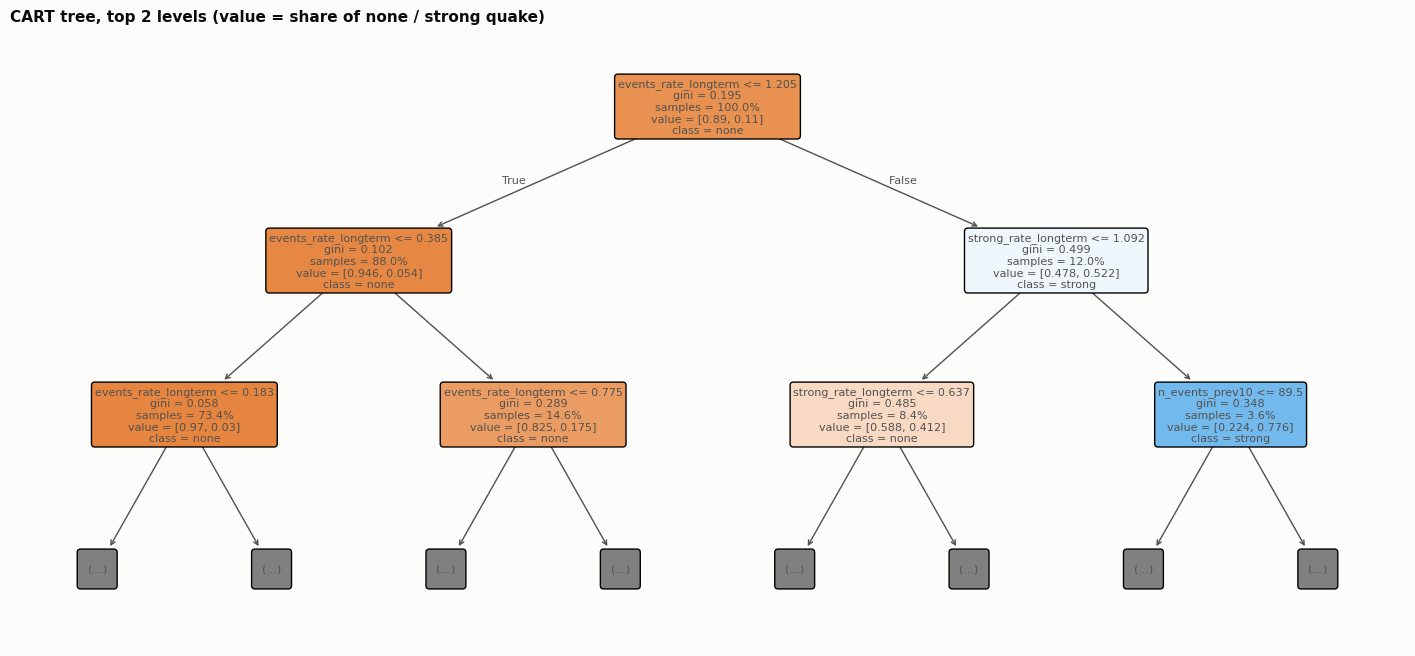

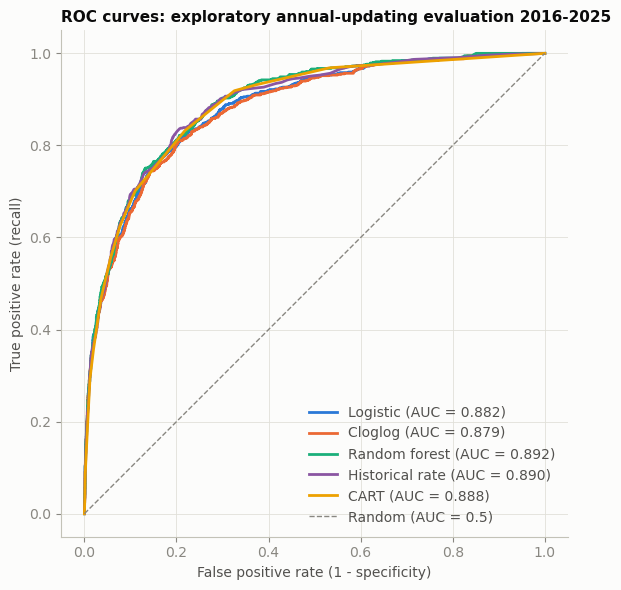

In [25]:
cart = run_cart(results)

### Model comparison and probability calibration
**ROC-AUC** measures ranking: do positive years tend to receive higher probabilities? **Calibration** asks whether, for example, predictions around 10% occur about 10% of the time. **Brier score** is the mean squared probability error; lower is better, but it alone does not establish calibration.

The plots compare mean predicted and observed frequencies in fixed probability bins. Points above the diagonal indicate underprediction; points below it indicate overprediction. Counts and positive outcomes are printed for every occupied bin. The min–max leave-one-evaluation-year-out range shows sensitivity to individual years; it is **not a confidence interval** and does not resolve spatial dependence. Sparse high-probability bins deserve particular caution. No probability correction is fitted using evaluation outcomes.


                      roc_auc   brier      f1  precision  recall  accuracy  threshold
Logistic               0.8821  0.0649  0.5298     0.4483  0.6474    0.8785       0.21
Cloglog                0.8788  0.0652  0.5247     0.4411  0.6474    0.8760       0.20
Random forest          0.8922  0.0638  0.5459     0.4739  0.6435    0.8868       0.25
Historical rate        0.8896  0.0644  0.5441     0.4594  0.6671    0.8819       0.21
CART                   0.8881  0.0650  0.5326     0.4294  0.7012    0.8699       0.18
Constant probability   0.5000  0.0945  0.0000     0.0000  0.0000    0.8943       1.00


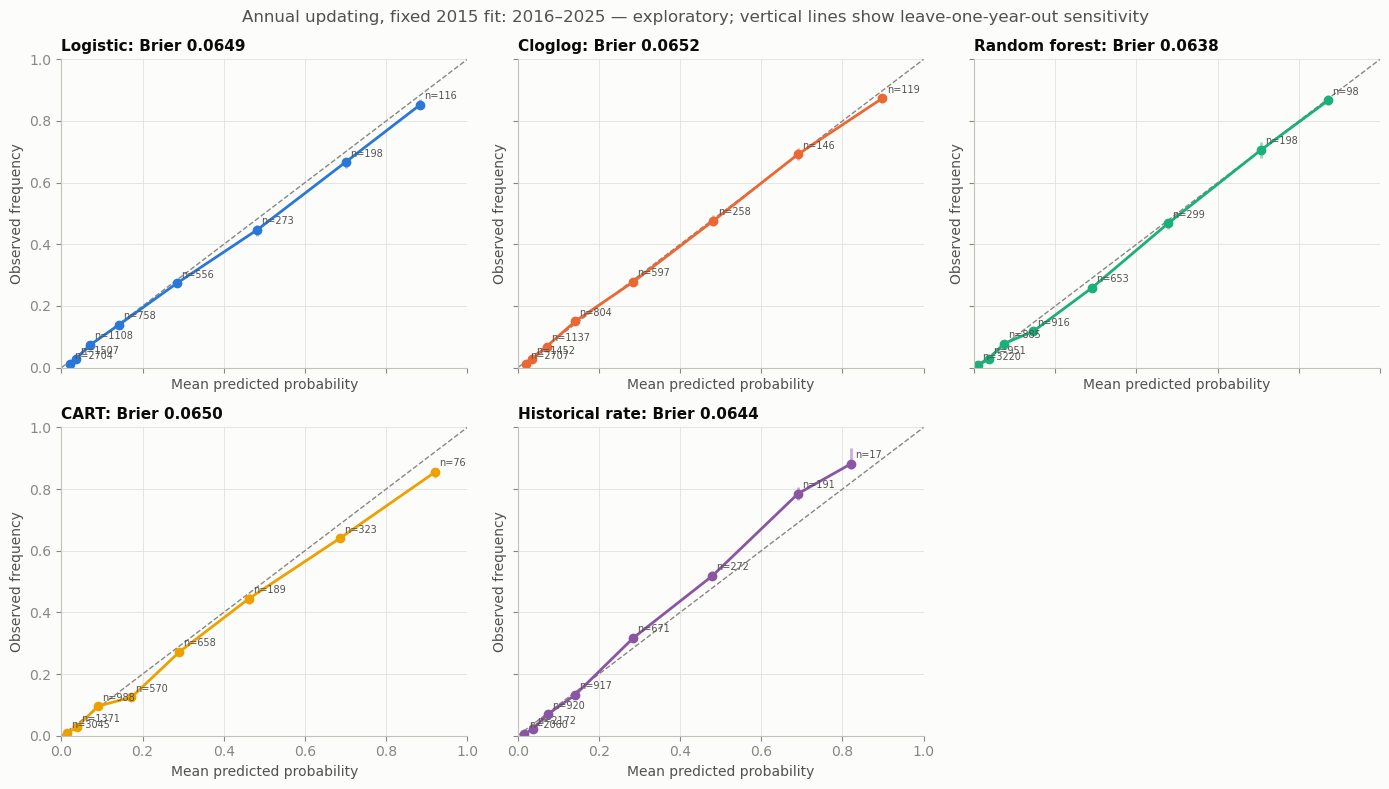

Aggregate direction is descriptive; bin deviations and uncertainty still matter.
          model  mean_predicted  observed  difference aggregate_direction
       Logistic          0.1141    0.1057      0.0084        overpredicts
        Cloglog          0.1116    0.1057      0.0059        overpredicts
  Random forest          0.1140    0.1057      0.0083        overpredicts
           CART          0.1177    0.1057      0.0121        overpredicts
Historical rate          0.1079    0.1057      0.0022        overpredicts


In [26]:
PROBABILITY_COLUMNS = {
    "Logistic": "p_logistic", "Cloglog": "p_cloglog",
    "Random forest": "p_random_forest", "CART": "p_cart",
    "Historical rate": "p_historical_rate",
}
CALIBRATION_EDGES = np.array([0, .025, .05, .10, .20, .40, .60, .80, 1.0])


def calibration_summary(predictions, probability_columns=PROBABILITY_COLUMNS):
    summaries = []
    for model, column in probability_columns.items():
        frame = predictions[["year", TARGET_COLUMN, column]].copy()
        assert frame[column].notna().all() and frame[column].between(0, 1).all()
        frame["bin"] = pd.cut(frame[column], CALIBRATION_EDGES, include_lowest=True)
        for interval, group in frame.groupby("bin", observed=True):
            sensitivity = [group.loc[group["year"].ne(year), TARGET_COLUMN].mean()
                           for year in group["year"].unique()
                           if group["year"].ne(year).any()]
            summaries.append({
                "model": model, "bin": str(interval), "region_years": len(group),
                "positive_years": int(group[TARGET_COLUMN].sum()),
                "predicted": group[column].mean(), "observed": group[TARGET_COLUMN].mean(),
                "leave_year_out_min": min(sensitivity) if sensitivity else np.nan,
                "leave_year_out_max": max(sensitivity) if sensitivity else np.nan,
            })
    return pd.DataFrame(summaries)


def plot_calibration(predictions, label, filename, probability_columns=PROBABILITY_COLUMNS):
    summary = calibration_summary(predictions, probability_columns)
    fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True)
    for ax, (model, column) in zip(axes.flat, probability_columns.items()):
        part = summary[summary["model"].eq(model)]
        ax.plot([0, 1], [0, 1], "--", color=INK_MUTED, linewidth=1)
        ax.vlines(part["predicted"], part["leave_year_out_min"], part["leave_year_out_max"],
                  color=MODEL_COLORS[model], alpha=.45)
        ax.plot(part["predicted"], part["observed"], "o-", color=MODEL_COLORS[model])
        for row in part.itertuples():
            ax.annotate(f"n={row.region_years}", (row.predicted, row.observed),
                        xytext=(3, 4), textcoords="offset points", fontsize=7)
        brier = brier_score_loss(predictions[TARGET_COLUMN], predictions[column])
        ax.set_title(f"{model}: Brier {brier:.4f}")
        ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability", ylabel="Observed frequency")
    for ax in list(axes.flat)[len(probability_columns):]:
        ax.set_visible(False)
    fig.suptitle(label + " — exploratory; vertical lines show leave-one-year-out sensitivity")
    fig.tight_layout()
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    comparison = []
    for model, column in probability_columns.items():
        predicted = predictions[column].mean()
        observed = predictions[TARGET_COLUMN].mean()
        direction = "overpredicts" if predicted > observed else "underpredicts" if predicted < observed else "matches"
        comparison.append({"model": model, "mean_predicted": predicted, "observed": observed,
                           "difference": predicted-observed, "aggregate_direction": direction})
    print("Aggregate direction is descriptive; bin deviations and uncertainty still matter.")
    print(pd.DataFrame(comparison).round(4).to_string(index=False))
    return summary


print(cart["metrics"][["roc_auc", "brier", "f1", "precision", "recall", "accuracy", "threshold"]].round(4).to_string())
# Archived refined metrics from original cells 66/69, not recomputed results.
original_reported = pd.DataFrame.from_dict({
    "Logistic": [0.8821, 0.0649, 0.5299],
    "Cloglog": [0.8788, 0.0652, 0.5247],
    "Random forest": [0.8922, 0.0638, 0.5438],
    "CART": [0.888, 0.065, 0.533],  # available saved precision only
    "Constant probability": [0.5, 0.0945, 0.0],
}, orient="index", columns=["roc_auc", "brier", "f1"])
before_after = original_reported.add_prefix("original_").join(
    cart["metrics"][["roc_auc", "brier", "f1"]].add_prefix("revised_"), how="outer")
before_after.to_csv(REVISED_DATA_DIR / "original_vs_revised_metrics.csv")
cart["metrics"].to_csv(REVISED_DATA_DIR / "fixed_fit_metrics_with_cart.csv")
evaluation_predictions = pd.read_csv(PREDICTIONS_FILE)
calibration_table = plot_calibration(
    evaluation_predictions, "Annual updating, fixed 2015 fit: 2016–2025",
    "fig15_calibration_fixed_fit.png")
calibration_table.to_csv(REVISED_DATA_DIR / "calibration_fixed_fit.csv", index=False)


### Findings: model performance and calibration
Evaluation covers **7,220 region-years**, including **763 positive years (10.57%)**.

| Model | ROC-AUC ↑ | Brier ↓ | F1 ↑ |
|---|---:|---:|---:|
| Logistic | 0.8821 | 0.06487 | 0.5298 |
| Cloglog | 0.8788 | 0.06522 | 0.5247 |
| Random forest | 0.8922 | 0.06383 | 0.5459 |
| CART | 0.8881 | 0.06503 | 0.5326 |
| Historical rate | 0.8896 | 0.06445 | 0.5441 |
| Constant probability | 0.5000 | 0.09453 | 0.0000 |

Random Forest lowers Brier score by only **0.96% relative to historical frequency**, without a significance assessment. The historical baseline beats Logistic, Cloglog and CART on both AUC and Brier.

All models overpredict overall: mean estimates range from 10.79% to 11.77%, versus 10.57% observed. Logistic's lowest bin predicts 2.03% versus 1.11% observed (n=2,704). Historical frequency underpredicts its 60–80% bin (69.07% versus 78.53%, n=191); its >80% bin has just **17 rows and 15 positives**. Strong ranking or Brier score does not establish perfect calibration.


### Rolling-origin reliability check
We repeat selection, tuning and refitting at origins **2016 and 2021**, then score disjoint five-year blocks. Each origin reserves the previous ten target years for validation; earlier target years and cells known by that fitting cutoff supply internal fitting. Final refitting uses only observations before the origin. Predictors update annually within each evaluation block.

This tests sensitivity to the fitting cutoff within the fixed 722-cell population. It does not create an independent holdout or resolve retrospective catalogue revisions.


Exploratory rolling-origin metrics by origin:
 origin                model  threshold  roc_auc  brier     f1
   2016             Logistic       0.21   0.8780 0.0669 0.5336
   2016              Cloglog       0.20   0.8756 0.0671 0.5339
   2016        Random forest       0.25   0.8864 0.0658 0.5492
   2016                 CART       0.18   0.8821 0.0671 0.5388
   2016      Historical rate       0.21   0.8817 0.0671 0.5449
   2016 Constant probability       1.00   0.5000 0.0983 0.0000
   2021             Logistic       0.25   0.8864 0.0628 0.5322
   2021              Cloglog       0.24   0.8823 0.0633 0.5247
   2021        Random forest       0.24   0.8980 0.0619 0.5396
   2021                 CART       0.26   0.8943 0.0636 0.5388
   2021      Historical rate       0.24   0.8965 0.0618 0.5442
   2021 Constant probability       1.00   0.5000 0.0907 0.0000
Combined disjoint blocks (classification cutoffs differ by origin):
                      roc_auc   brier      f1
model                

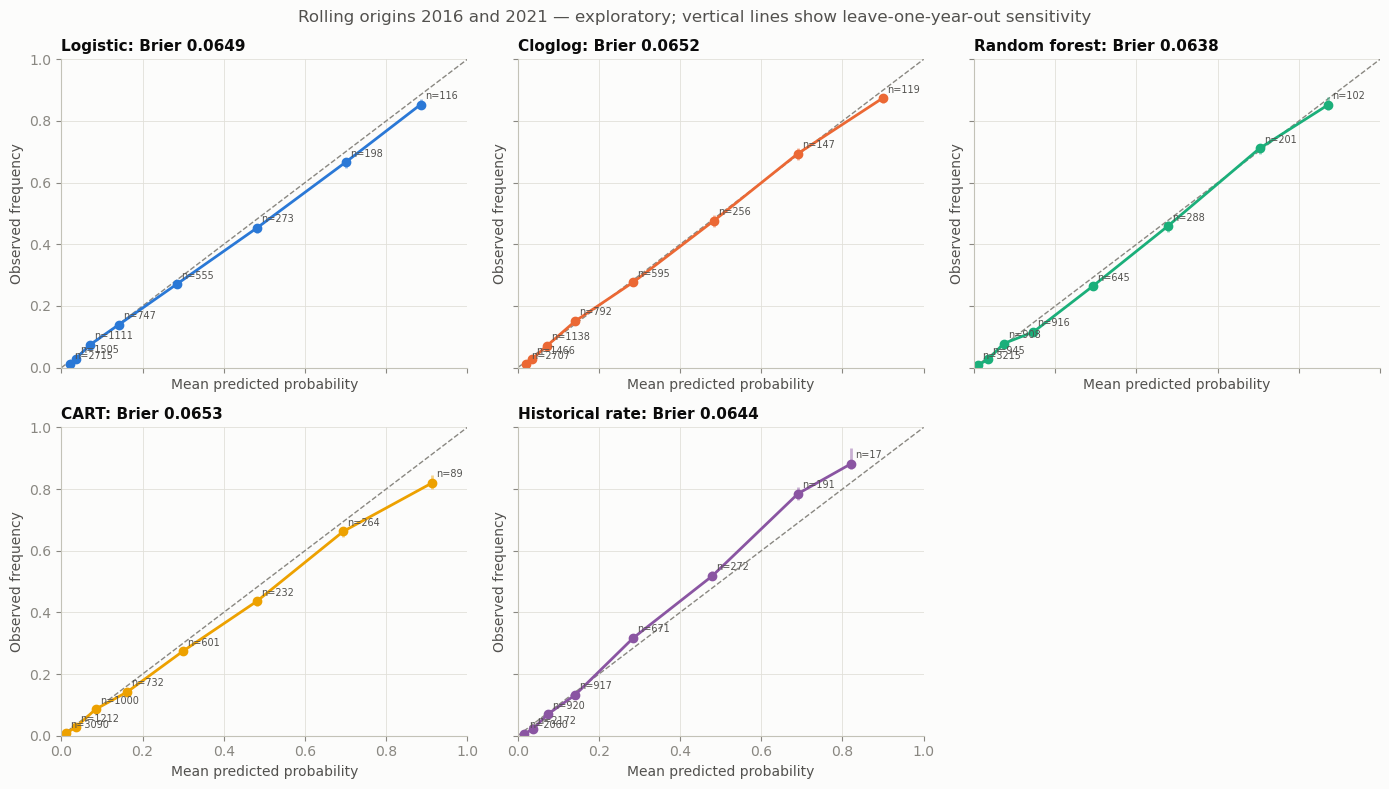

Aggregate direction is descriptive; bin deviations and uncertainty still matter.
          model  mean_predicted  observed  difference aggregate_direction
       Logistic          0.1139    0.1057      0.0083        overpredicts
        Cloglog          0.1114    0.1057      0.0058        overpredicts
  Random forest          0.1140    0.1057      0.0084        overpredicts
           CART          0.1164    0.1057      0.0107        overpredicts
Historical rate          0.1079    0.1057      0.0022        overpredicts


In [27]:
def rolling_origin_backtest(table, origins=(2016, 2021), block_years=5):
    all_predictions, metric_rows, protocols = [], [], []
    for origin in origins:
        fit_end = origin - 11
        train = table[table["year"].lt(origin) & table["first_observed_year"].lt(origin)]
        known_for_tuning = train["first_observed_year"].le(fit_end)
        subtrain = train[known_for_tuning & train["year"].le(fit_end)]
        validation = train[known_for_tuning & train["year"].gt(fit_end)]
        test = table[table["year"].between(origin, origin + block_years - 1)
                     & table["cell_id"].isin(train["cell_id"].unique())]
        if min(len(subtrain), len(validation), len(test)) == 0:
            raise ValueError(f"Insufficient rows at origin {origin}")
        assert subtrain["year"].max() < validation["year"].min()
        assert train["year"].max() < test["year"].min()
        predicted = test[["cell_id", "year", TARGET_COLUMN]].copy()
        predicted["origin"] = origin
        thresholds = {}
        selected_at_origin = {}
        select_scaled, _ = standardize(subtrain, [], GLM_FEATURES)
        for name, link in [("Logistic", "logit"), ("Cloglog", "cloglog")]:
            selected = backward_elimination(select_scaled, subtrain[TARGET_COLUMN], link, "aic")
            selected_at_origin[name] = selected
            sub_scaled, (val_scaled,) = standardize(subtrain, [validation], selected)
            sub_model = fit_glm(sub_scaled, subtrain[TARGET_COLUMN], link)
            val_p = sub_model.predict(sm.add_constant(val_scaled, has_constant="add"))
            thresholds[name] = best_f1_threshold(validation[TARGET_COLUMN], val_p)
            train_scaled, (test_scaled,) = standardize(train, [test], selected)
            model = fit_glm(train_scaled, train[TARGET_COLUMN], link)
            predicted[PROBABILITY_COLUMNS[name]] = np.asarray(
                model.predict(sm.add_constant(test_scaled, has_constant="add")))
        params, _ = tune_cart(subtrain, validation)
        for name, features, fitter in [
                ("Random forest", FOREST_FEATURES, fit_random_forest),
                ("CART", CART_FEATURES, lambda x, y: fit_cart(x, y, **params))]:
            sub_model = fitter(subtrain[features], subtrain[TARGET_COLUMN])
            thresholds[name] = best_f1_threshold(
                validation[TARGET_COLUMN], sub_model.predict_proba(validation[features])[:, 1])
            model = fitter(train[features], train[TARGET_COLUMN])
            predicted[PROBABILITY_COLUMNS[name]] = model.predict_proba(test[features])[:, 1]
        thresholds["Historical rate"] = best_f1_threshold(
            validation[TARGET_COLUMN], historical_rate_predictions(validation))
        predicted["p_historical_rate"] = historical_rate_predictions(test)
        predicted["p_constant"] = train[TARGET_COLUMN].mean()
        columns = {**PROBABILITY_COLUMNS, "Constant probability": "p_constant"}
        thresholds["Constant probability"] = 1.0
        for name, column in columns.items():
            predicted["class_" + column] = (predicted[column] >= thresholds[name]).astype(int)
            metric_rows.append({"origin": origin, "model": name,
                                **evaluate_predictions(test[TARGET_COLUMN], predicted[column], thresholds[name])})
        protocols.append({"origin": origin, "feature_selection_end": fit_end,
                          "validation_end": origin - 1, "evaluation_end": int(test["year"].max()),
                          "selected_features": selected_at_origin, "cart_params": params})
        all_predictions.append(predicted)
    combined = pd.concat(all_predictions, ignore_index=True)
    assert not combined.duplicated(["cell_id", "year"]).any()
    fold_metrics = pd.DataFrame(metric_rows)
    aggregate = []
    for name, column in {**PROBABILITY_COLUMNS, "Constant probability": "p_constant"}.items():
        # Thresholds differ by origin: classification summaries use each row's stored label.
        scores = evaluate_predictions(combined[TARGET_COLUMN], combined[column], .5)
        labels = combined["class_" + column]
        tn, fp, fn, tp = confusion_matrix(combined[TARGET_COLUMN], labels, labels=[0, 1]).ravel()
        scores.update(threshold=np.nan, accuracy=accuracy_score(combined[TARGET_COLUMN], labels),
                      precision=precision_score(combined[TARGET_COLUMN], labels, zero_division=0),
                      recall=recall_score(combined[TARGET_COLUMN], labels, zero_division=0),
                      f1=f1_score(combined[TARGET_COLUMN], labels, zero_division=0),
                      specificity=tn/(tn+fp) if tn+fp else np.nan, TP=tp, FP=fp, TN=tn, FN=fn)
        aggregate.append({"model": name, **scores})
    aggregate = pd.DataFrame(aggregate).set_index("model")
    combined.to_csv(REVISED_DATA_DIR / "rolling_origin_predictions.csv", index=False)
    fold_metrics.to_csv(REVISED_DATA_DIR / "rolling_origin_fold_metrics.csv", index=False)
    aggregate.to_csv(REVISED_DATA_DIR / "rolling_origin_metrics.csv")
    (REVISED_DATA_DIR / "rolling_origin_protocol.json").write_text(json.dumps(protocols, indent=2))
    print("Exploratory rolling-origin metrics by origin:")
    print(fold_metrics[["origin", "model", "threshold", "roc_auc", "brier", "f1"]].round(4).to_string(index=False))
    print("Combined disjoint blocks (classification cutoffs differ by origin):")
    print(aggregate[["roc_auc", "brier", "f1"]].round(4).to_string())
    return {"predictions": combined, "fold_metrics": fold_metrics, "metrics": aggregate}


if RUN_ROLLING_ORIGIN:
    rolling = rolling_origin_backtest(load_modelling_table())
    rolling_calibration = plot_calibration(
        rolling["predictions"], "Rolling origins 2016 and 2021",
        "fig16_calibration_rolling_origin.png")
    rolling_calibration.to_csv(REVISED_DATA_DIR / "calibration_rolling_origin.csv", index=False)
else:
    print("Rolling-origin evaluation skipped by RUN_ROLLING_ORIGIN; no reliability claim follows.")


### Real-data findings: rolling-origin evaluation
Both origins completed and cover disjoint 2016–2020 and 2021–2025 blocks. Combined results are:

| Model | ROC-AUC ↑ | Brier ↓ | F1 ↑ |
|---|---:|---:|---:|
| Logistic | 0.8818 | 0.06486 | 0.5330 |
| Cloglog | 0.8785 | 0.06520 | 0.5296 |
| Random forest | 0.8914 | 0.06383 | 0.5445 |
| CART | 0.8891 | 0.06531 | 0.5388 |
| Historical rate | 0.8896 | 0.06445 | 0.5445 |
| Constant probability | 0.4872 | 0.09453 | 0.0000 |

Random Forest's fold Brier scores are 0.06578 and 0.06187; the historical-rate baseline's are 0.06709 and 0.06181. The baseline slightly outperforms the forest in the second block, so there is no consistent large model advantage. This is descriptive variation, not a statistical significance claim.

The historical baseline has identical probabilities in fixed-fit and rolling runs because it already updates annually using all preceding years; its classification cutoffs differ by origin. The pooled rolling constant baseline has AUC 0.4872 rather than 0.5 because its constant differs between blocks; each block separately has AUC 0.5. Both evaluation designs remain exploratory.

## 10. Earthquake probability forecasting
After historical evaluation, the selected structures are refitted on target years **1975–2025** to estimate 2026 probabilities using history through 2025. Coefficients, tree boundaries and class labels may differ from the historical evaluation fits. No 2026 outcome evaluation is included.

The optional **Poisson-equivalent interval** is `1 / [−log(1−p)]`. It describes mean inter-event spacing only under a stationary Poisson assumption, not a countdown or geological recurrence estimate. Forecasting annual occurrence does not require this conversion.

Logistic and CART support interpretable pricing examples; this is a teaching choice, not a claim that they predict best. Random Forest and the historical baseline score better.


In [28]:
"""Illustrate 2026 regional probabilities and fixed-payout parametric pricing.

One fixed annual payout is triggered by at least one M >= 6.0 earthquake in
one 5-degree cell. Forecast features combine the previous ten years and the
expanding record since 1965, always ending before 2026. Logistic is refitted
on target years 1975-2025 after exploratory historical evaluation.

Expected payout = annual probability x fixed payout.
Illustrative premium = expected payout x (1 + loading).
The Poisson-equivalent interval is an assumption-dependent description,
not a forecast date or geological recurrence estimate.

Historical prices use annually updated 2016-2025 predictors and models fitted
through 2015. This is previously inspected exploratory evidence, not a fixed
decade forecast issued in 2015 or independent validation. Location coordinates
select whole regions, not city damage probabilities. Required functions are
defined in earlier cells of this notebook.
"""

from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


FORECAST_YEAR = 2026
FORECAST_FILE = REVISED_DATA_DIR / "risk_forecast_2026.csv"
TEST_PREDICTIONS_FILE = REVISED_DATA_DIR / "test_predictions.csv"
FIGURE_DIR = REVISED_FIG_DIR

DEFAULT_PAYOUT_EUR = 10_000_000
DEFAULT_LOADING = 0.30  # covers capital costs, expenses and profit
DEFAULT_CLOGLOG_FEATURES = ["log_events_prev10", "max_mag_prev10", "years_since_strong",
                            "share_shallow_prev10", "abs_lat"]

# Absolute probability bands an underwriter can read directly
TIER_EDGES = [0.0, 0.025, 0.10, 0.30, 1.0]
TIER_NAMES = ["Low", "Moderate", "High", "Very high"]
TIER_COLORS = ["#f0956b", "#eb6834", "#b8461c", "#7a2a0c"]  # light to dark orange


# ---------------------------------------------------------------- forecast

def build_forecast_features(forecast_year: int = FORECAST_YEAR) -> pd.DataFrame:
    """Build the feature rows for the forecast year from the preceding history.

    The forecast year is appended to the annual panel with placeholder values;
    because every feature only uses earlier years, the placeholders never
    enter the features.

    Args:
        forecast_year: Year to forecast (the year after the last catalogue year).

    Returns:
        One row per grid cell with identifiers and all model features.
    """
    catalog = assign_grid_cells(load_clean_catalog())
    panel = build_annual_panel(catalog, STRONG_MAGNITUDE)
    cells = panel[["cell_id", "cell_lat", "cell_lon"]].drop_duplicates()
    future_rows = cells.assign(year=forecast_year, n_events=0, n_strong=0, n_shallow=0,
                               max_mag=NO_EVENT_MAGNITUDE)
    panel = add_history_features(pd.concat([panel, future_rows], ignore_index=True))
    forecast = panel[panel["year"] == forecast_year].copy()
    forecast["log_events_prev1"] = np.log1p(forecast["n_events_prev1"])
    return forecast.reset_index(drop=True)


def probability_to_rate(probability: pd.Series) -> pd.Series:
    """Convert a yearly probability of at least one event into a Poisson rate.

    P = 1 - exp(-rate)  <=>  rate = -ln(1 - P).

    Args:
        probability: Probability of at least one strong quake in a year.

    Returns:
        Expected number of strong quakes per year.
    """
    return -np.log1p(-probability)


def assign_risk_tier(probability: pd.Series) -> pd.Series:
    """Assign each region to a risk tier by its yearly trigger probability.

    Args:
        probability: Probability of at least one strong quake in a year.

    Returns:
        Ordered categorical series with the tier names.
    """
    return pd.cut(probability, bins=TIER_EDGES, labels=TIER_NAMES, include_lowest=True)


def price_policy(probability: pd.Series, payout: float = DEFAULT_PAYOUT_EUR,
                 loading: float = DEFAULT_LOADING) -> pd.DataFrame:
    """Price a parametric cover that pays `payout` if the trigger occurs.

    Args:
        probability: Yearly trigger probability per region.
        payout: Fixed payout in EUR.
        loading: Safety/expense loading added on top of the expected loss.

    Returns:
        DataFrame with expected loss, premium and rate on line
        (premium as a share of the payout, the usual market quote).
    """
    expected_loss = probability * payout
    premium = expected_loss * (1 + loading)
    return pd.DataFrame({"expected_loss_eur": expected_loss, "premium_eur": premium,
                         "rate_on_line": premium / payout})


def forecast_risk(selected_features: list[str], forecast_year: int = FORECAST_YEAR,
                  payout: float = DEFAULT_PAYOUT_EUR, loading: float = DEFAULT_LOADING
                  ) -> pd.DataFrame:
    """Fit the final logistic model on all years and forecast every region.

    Args:
        selected_features: Features of the AIC-selected logistic model.
        forecast_year: Year to forecast.
        payout: Fixed payout in EUR for pricing.
        loading: Premium loading.

    Returns:
        Forecast table with probability, rate, return period, tier and price.
    """
    history = load_modelling_table()
    forecast = build_forecast_features(forecast_year)
    history_scaled, (forecast_scaled,) = standardize(history, [forecast], selected_features)
    model = fit_glm(history_scaled, history["strong_quake"], "logit")

    forecast["probability"] = np.asarray(
        model.predict(sm.add_constant(forecast_scaled, has_constant="add")))
    forecast["annual_rate"] = probability_to_rate(forecast["probability"])
    forecast["poisson_equivalent_interval_years"] = 1 / forecast["annual_rate"]
    forecast["risk_tier"] = assign_risk_tier(forecast["probability"])
    forecast = pd.concat([forecast, price_policy(forecast["probability"], payout, loading)], axis=1)

    output_columns = (["cell_id", "cell_lat", "cell_lon", "probability", "annual_rate",
                       "poisson_equivalent_interval_years", "risk_tier", "expected_loss_eur", "premium_eur",
                       "rate_on_line"]
                      + list(dict.fromkeys(selected_features + ["log_events_prev10", "years_since_strong", "strong_rate_longterm"])))
    forecast = forecast[output_columns].sort_values("probability", ascending=False)
    FORECAST_FILE.parent.mkdir(parents=True, exist_ok=True)
    forecast.to_csv(FORECAST_FILE, index=False)
    return forecast.reset_index(drop=True)


# ---------------------------------------------------------------- backtest

def backtest_pricing(payout: float = DEFAULT_PAYOUT_EUR, loading: float = DEFAULT_LOADING,
                     probability_column: str = "p_logistic") -> pd.DataFrame:
    """Compare premiums and payouts in the test period 2016-2025, per tier.

    The test probabilities come from the model trained on 1975-2015 only, so
    this is a chronological but previously inspected exploratory check. The loss ratio is payouts divided
    by premiums; with a 30% loading a well-calibrated model should land near
    1 / 1.3 = 77%. Flat pricing charges every region the same average price.

    Args:
        payout: Fixed payout in EUR.
        loading: Premium loading.
        probability_column: Column of test_predictions.csv to price with.

    Returns:
        Table per risk tier (plus a total row) with calibration and loss ratios.
    """
    test = pd.read_csv(TEST_PREDICTIONS_FILE)
    train_base_rate = load_modelling_table().query("split == 'train'")["strong_quake"].mean()

    test["risk_tier"] = assign_risk_tier(test[probability_column])
    test["premium_risk_based"] = price_policy(test[probability_column], payout, loading)["premium_eur"]
    test["premium_flat"] = train_base_rate * payout * (1 + loading)
    test["payout"] = test["strong_quake"] * payout

    grouped = test.groupby("risk_tier", observed=False)
    table = pd.DataFrame({
        "region_years": grouped.size(),
        "mean_predicted_p": grouped[probability_column].mean(),
        "observed_frequency": grouped["strong_quake"].mean(),
        "premiums_risk_based_m": grouped["premium_risk_based"].sum() / 1e6,
        "premiums_flat_m": grouped["premium_flat"].sum() / 1e6,
        "payouts_m": grouped["payout"].sum() / 1e6,
    })
    table.loc["Total"] = [len(test), test[probability_column].mean(), test["strong_quake"].mean(),
                          test["premium_risk_based"].sum() / 1e6, test["premium_flat"].sum() / 1e6,
                          test["payout"].sum() / 1e6]
    table["loss_ratio_risk_based"] = table["payouts_m"] / table["premiums_risk_based_m"]
    table["loss_ratio_flat"] = table["payouts_m"] / table["premiums_flat_m"]
    return table


# ---------------------------------------------------------------- figures

def plot_risk_map(forecast: pd.DataFrame, file_name: str = "fig11_risk_map_2026.png"):
    """Map the 2026 risk tier of every region (uses cartopy if installed).

    Args:
        forecast: Output of forecast_risk.
        file_name: File name for the saved figure.
    """
    n_lat, n_lon = 180 // GRID_SIZE_DEGREES, 360 // GRID_SIZE_DEGREES
    tier_grid = np.full((n_lat, n_lon), np.nan)
    rows = ((forecast["cell_lat"] - GRID_SIZE_DEGREES / 2 + 90) // GRID_SIZE_DEGREES).astype(int)
    cols = ((forecast["cell_lon"] - GRID_SIZE_DEGREES / 2 + 180) // GRID_SIZE_DEGREES).astype(int)
    tier_grid[rows, cols] = forecast["risk_tier"].cat.codes
    lon_edges = np.arange(-180, 181, GRID_SIZE_DEGREES)
    lat_edges = np.arange(-90, 91, GRID_SIZE_DEGREES)
    mesh_style = {"cmap": ListedColormap(TIER_COLORS), "vmin": -0.5, "vmax": 3.5}

    try:
        import cartopy.crs as ccrs
        fig, ax = plt.subplots(figsize=(13, 7),
                               subplot_kw={"projection": ccrs.Robinson(central_longitude=150)})
        ax.set_global()
        ax.coastlines(resolution="110m", color="#888780", linewidth=0.5, zorder=2)
        ax.pcolormesh(lon_edges, lat_edges, np.ma.masked_invalid(tier_grid),
                      transform=ccrs.PlateCarree(), zorder=1, **mesh_style)
    except ImportError:  # plain longitude-latitude plot without coastlines
        fig, ax = plt.subplots(figsize=(13, 6.5))
        ax.pcolormesh(lon_edges, lat_edges, np.ma.masked_invalid(tier_grid), **mesh_style)
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.set_aspect("equal")

    counts = forecast["risk_tier"].value_counts()
    bounds = ["0–2.5% inclusive", ">2.5–10%", ">10–30%", ">30–100%"]
    handles = [Patch(facecolor=color, label=f"{name} ({bound}): {counts.get(name, 0)} regions")
               for name, color, bound in zip(TIER_NAMES, TIER_COLORS, bounds)]
    handles.append(Patch(facecolor="white", edgecolor="#888780",
                         label="Blank: outside model scope, not zero risk"))
    ax.legend(handles=handles, title=f"P(M >= {STRONG_MAGNITUDE}) in {FORECAST_YEAR}",
              loc="lower left", frameon=True, framealpha=0.9)
    ax.set_title(f"Regional occurrence probability (not city damage risk), 5° cells, {FORECAST_YEAR}")
    fig.tight_layout()
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_DIR / file_name, dpi=200, bbox_inches="tight")
    plt.show()


def plot_loss_ratios(backtest: pd.DataFrame, loading: float = DEFAULT_LOADING,
                     file_name: str = "fig12_loss_ratios.png"):
    """Compare loss ratios of risk-based and flat pricing per tier.

    Args:
        backtest: Output of backtest_pricing.
        loading: Premium loading, used for the target-loss-ratio reference line.
        file_name: File name for the saved figure.
    """
    tiers = [tier for tier in TIER_NAMES if backtest.loc[tier, "region_years"] > 0]
    positions = np.arange(len(tiers))
    width = 0.38
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.bar(positions - width / 2, backtest.loc[tiers, "loss_ratio_risk_based"] * 100, width,
           color="#2a78d6", label="Risk-based pricing (our model)")
    ax.bar(positions + width / 2, backtest.loc[tiers, "loss_ratio_flat"] * 100, width,
           color="#898781", label="Flat pricing (same price everywhere)")
    ax.axhline(100 / (1 + loading), color="#0b0b0b", linestyle="--", linewidth=1)
    ax.text(-0.45, 100 / (1 + loading) + 3, f"target {100 / (1 + loading):.0f}%",
            ha="left", color="#0b0b0b")
    ax.set_xticks(positions, tiers)
    ax.set_ylabel("Loss ratio = payouts / premiums (%)")
    ax.set_title("Backtest 2016-2025: loss ratio per risk tier")
    ax.legend(loc="upper left")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / file_name, dpi=200, bbox_inches="tight")
    plt.show()


# ---------------------------------------------------------------- quotes

def find_cell_id(latitude: float, longitude: float, grid_size: int = GRID_SIZE_DEGREES) -> str:
    """Return the grid-cell id that contains a coordinate.

    Args:
        latitude: Latitude in degrees (-90 to 90).
        longitude: Longitude in degrees (-180 to 180).
        grid_size: Cell edge length in degrees.

    Returns:
        Cell id in the same format as build_features.assign_grid_cells.
    """
    if not -90 <= latitude <= 90 or not -180 <= longitude <= 180:
        raise ValueError("Coordinates outside physical ranges.")
    # +180 and -180 represent the same meridian; +90 belongs to the last latitude band.
    longitude = (longitude + 180) % 360 - 180
    latitude = min(latitude, np.nextafter(90.0, -np.inf))
    lat_edge = int(np.floor(latitude / grid_size) * grid_size)
    lon_edge = int(np.floor(longitude / grid_size) * grid_size)
    return f"{lat_edge}_{lon_edge}"


def quote_location(latitude: float, longitude: float, forecast: pd.DataFrame,
                   payout: float = DEFAULT_PAYOUT_EUR, loading: float = DEFAULT_LOADING) -> dict:
    """Quote the parametric cover for the region that contains a location.

    Args:
        latitude: Latitude of the insured location.
        longitude: Longitude of the insured location.
        forecast: Output of forecast_risk.
        payout: Fixed payout in EUR.
        loading: Premium loading.

    Returns:
        Dictionary with the region's probability, tier, return period and
        premium, or a note if the region has no recorded M >= 5.5 activity.
    """
    cell_id = find_cell_id(latitude, longitude)
    match = forecast[forecast["cell_id"] == cell_id]
    if match.empty:
        return {"cell_id": cell_id, "status": "outside model scope",
                "note": "No M >= 5.5 earthquake recorded in this region 1965-2015, so the "
                        "catalogue gives no basis for a model-based price. Hazard is not assumed "
                        "zero: faults with very long recurrence times can be missed."}
    region = match.iloc[0]
    price = price_policy(pd.Series([region["probability"]]), payout, loading).iloc[0]
    return {
        "cell_id": cell_id,
        "probability_2026": round(float(region["probability"]), 4),
        "poisson_equivalent_interval_years": round(float(region["poisson_equivalent_interval_years"]), 1),
        "risk_tier": str(region["risk_tier"]),
        "expected_loss_eur": round(float(price["expected_loss_eur"])),
        "premium_eur": round(float(price["premium_eur"])),
        "rate_on_line": f"{price['rate_on_line']:.2%}",
        "events_last_10_years": int(np.expm1(region["log_events_prev10"]).round()),
        "years_since_strong": int(region["years_since_strong"]),
        "strong_quakes_per_year_since_1965": round(float(region["strong_rate_longterm"]), 3),
    }


# ---------------------------------------------------------------- pipeline

EXAMPLE_LOCATIONS = {
    "Tokyo": (35.68, 139.69), "Istanbul": (41.01, 28.98), "Santiago de Chile": (-33.45, -70.67),
    "Kathmandu": (27.72, 85.32), "San Francisco": (37.77, -122.42), "Frankfurt": (50.11, 8.68),
}


def run_insurance_layer(selected_features: list[str] | None = None,
                        payout: float = DEFAULT_PAYOUT_EUR, loading: float = DEFAULT_LOADING,
                        make_plots: bool = True) -> dict:
    """Run the forecast, backtest and example quotes, and print the results.

    Args:
        selected_features: Explicit predictors of the Logistic model, frozen
            during the internal fitting stage; no implicit default is used.
        payout: Fixed payout in EUR.
        loading: Premium loading.
        make_plots: If True, draw and save the risk map and loss-ratio chart.

    Returns:
        Dictionary with the forecast table, backtest table and example quotes.
    """
    if selected_features is None:
        raise ValueError("Pass the predictors frozen during internal fitting explicitly.")
    features = selected_features
    forecast = forecast_risk(features, payout=payout, loading=loading)
    backtest = backtest_pricing(payout, loading)
    quotes = pd.DataFrame({city: quote_location(lat, lon, forecast, payout, loading)
                           for city, (lat, lon) in EXAMPLE_LOCATIONS.items()}).T

    print(f"=== {FORECAST_YEAR} forecast: {len(forecast)} regions, payout EUR {payout:,.0f}, "
          f"loading {loading:.0%} ===")
    print(forecast.groupby("risk_tier", observed=False).agg(
        regions=("cell_id", "size"), mean_probability=("probability", "mean"),
        mean_premium_eur=("premium_eur", "mean")).round(3).to_string())
    print(f"\n=== Backtest 2016-2025 (target loss ratio {1 / (1 + loading):.0%}) ===")
    print(backtest[["region_years", "mean_predicted_p", "observed_frequency", "loss_ratio_risk_based", "loss_ratio_flat"]].round(3).to_string())

    if make_plots:
        plot_risk_map(forecast)
        plot_loss_ratios(backtest, loading)

    return {"forecast": forecast, "backtest": backtest, "quotes": quotes}


## 11. Illustrative parametric insurance pricing
A parametric policy pays a predefined amount when a measurable trigger occurs. Here the assumption is **one fixed annual payment** if any M ≥ 6.0 earthquake occurs within the region; multiple qualifying events do not create multiple annual payments.

- **Predicted earthquake probability:** the model's annual regional occurrence estimate.
- **Expected fixed payout:** probability × fixed payout; an average over hypothetical repetitions.
- **Illustrative premium:** expected payout × 1.30, or expected payout / target loss ratio.
- **Target loss ratio:** intended expected payouts divided by premiums; a 30% loading corresponds to 1/1.30 ≈ 76.9%, not exactly 77%.
- **Historical loss ratio:** actual simulated payouts divided by collected simulated premiums, using annual historical model predictions.
- **Risk tiers/classes:** probability bands or fitted tree leaves; neither is a geological hazard classification.

These calculations omit actual property damage, exposure, vulnerability, correlated portfolio losses, capital, reinsurance and realistic expenses. A 30% premium-to-payout ceiling is an illustrative screen, not a commercial insurability decision. A low historical loss ratio may indicate overpricing relative to observed outcomes; it is not automatically evidence of a better model. Historical tier ratios do not validate a location's 2026 quote.


=== 2026 forecast: 722 regions, payout EUR 10,000,000, loading 30% ===
           regions  mean_probability  mean_premium_eur
risk_tier                                             
Low            289             0.020        259237.074
Moderate       253             0.051        667873.478
High            98             0.171       2218587.264
Very high       82             0.552       7171773.526

=== Backtest 2016-2025 (target loss ratio 77%) ===
           region_years  mean_predicted_p  observed_frequency  loss_ratio_risk_based  loss_ratio_flat
risk_tier                                                                                            
Low              2704.0             0.020               0.011                  0.421            0.078
Moderate         2615.0             0.050               0.047                  0.721            0.330
High             1106.0             0.174               0.175                  0.772            1.223
Very high         795.0             0

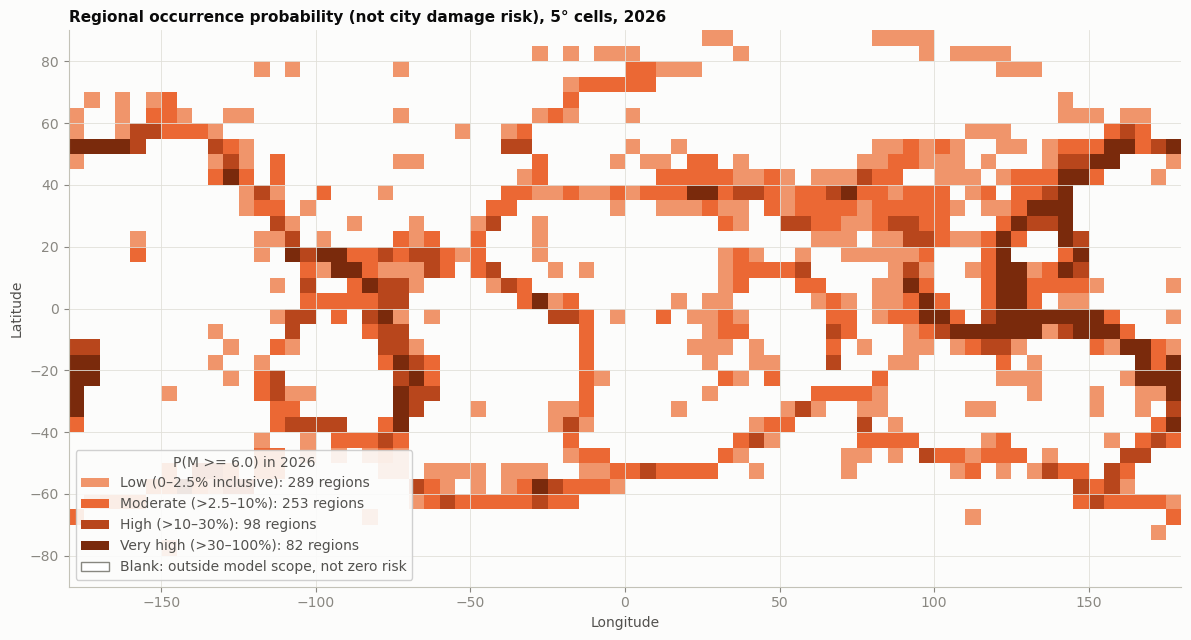

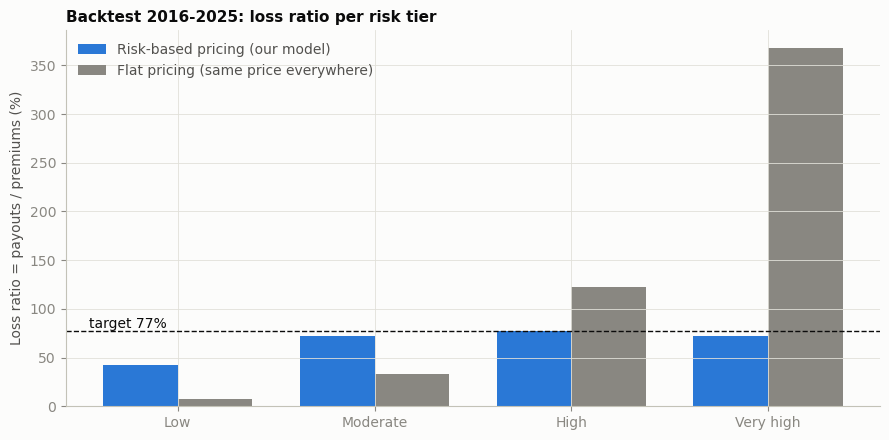

In [29]:
insurance = run_insurance_layer(results["selected_features"]["logit"])

In [30]:
MAX_RATE_ON_LINE = 0.30  # illustrative premium / payout ceiling; not a commercial decision

forecast = insurance["forecast"]
forecast["within_assumed_price_ceiling"] = forecast["rate_on_line"] <= MAX_RATE_ON_LINE
forecast.groupby("risk_tier", observed=False)["within_assumed_price_ceiling"].agg(within_assumed_ceiling="sum", regions="size");


In [31]:
forecast = insurance["forecast"]
forecast["within_assumed_price_ceiling"] = forecast["rate_on_line"].le(MAX_RATE_ON_LINE)
ceiling_summary = forecast.groupby("risk_tier", observed=False).agg(
    within_assumed_ceiling=("within_assumed_price_ceiling", "sum"), regions=("cell_id", "size"))
print(ceiling_summary.to_string())
print("Regions above the illustrative ceiling:", int((~forecast["within_assumed_price_ceiling"]).sum()))
print("This ceiling does not establish commercial insurability.")


           within_assumed_ceiling  regions
risk_tier                                 
Low                           289      289
Moderate                      253      253
High                           83       98
Very high                       0       82
Regions above the illustrative ceiling: 97
This ceiling does not establish commercial insurability.


### Findings: illustrative pricing
For a EUR 10M payout and **30% loading**, the logistic historical loss ratio is **71.2%**, versus a **76.9% target**. Tier ratios are 42.1% Low, 72.1% Moderate, 77.2% High and 72.0% Very high. In the Low tier, 2.03% was predicted versus 1.11% observed (30 positives among 2,704 rows): pricing overstates risk relative to observed outcomes.

Flat-pricing ratios are 7.8%, 33.0%, 122.3% and 367.6%, illustrating cross-subsidy rather than demonstrating customer selection or commercial profitability.

An **exact 77% target** changes the Logistic total to 71.3%; CART gives 69.1% at that same target. The difference between models reflects probability estimates, not target rounding.

The forecast has **722 regions**, of which **97 exceed the assumed 30% premium/payout ceiling**: 15 High and 82 Very high. This is an illustrative design assumption, not a commercial insurability decision.


### Experience adjustments
The adjustment blends each historical tier's observed/predicted ratio toward 1 using `Z = min(1, sqrt(n/1082))`, where n counts positive region-years. The approximate 1,082-event Poisson standard corresponds to a 90%/5% fluctuation criterion, but is only an illustrative weighting rule for dependent binary earthquake outcomes.

Factors use **2016–2025 outcomes and cannot be independently evaluated on those same years**. Final refits can change tiers and tree classes. Report base and adjusted premiums separately; a tier-level historical ratio is not a location-specific backtest or a future guarantee.


In [32]:
"""Compare Logistic and CART premiums for an illustrative target loss ratio.

Expected loss ratio = probability x fixed payout / premium.
Premium = probability x fixed payout / target loss ratio.
A 30% loading gives a target of 1/1.30 (about 76.9%); an exact 77% target
is slightly different. The realized historical loss ratio can differ from
that target through prediction error and random variation.

The experience adjustment blends a tier's observed/predicted ratio toward 1:
Z = min(1, sqrt(positive region-years / 1082)); factor = Z x ratio + (1-Z).
The approximate 1082-event Poisson fluctuation standard is only illustrative
for dependent binary region-year data. It is not validated earthquake
credibility. The adjustment uses 2016-2025 outcomes and cannot be evaluated
as a new improvement on those same outcomes. A 2026 refit uses history
through 2025; no later earthquake outcomes enter the prices.
"""

FULL_CREDIBILITY_EVENTS = 1082
DEFAULT_TARGET_LOSS_RATIO = 1 / (1 + DEFAULT_LOADING)  # 77%, i.e. a 30% loading
PRICING_MODELS = {"Logistic": "p_logistic", "CART": "p_cart"}


def experience_factors(probability_column: str) -> pd.DataFrame:
    """Compare predicted and observed frequencies per risk tier in 2016-2025.

    Uses the test predictions of the models trained on 1975-2015 only.

    Args:
        probability_column: Column of test_predictions.csv, e.g. "p_logistic".

    Returns:
        Per tier: predicted and observed frequency, number of strong-quake
        region-years, credibility Z and the credibility-weighted factor.
    """
    test = pd.read_csv(PREDICTIONS_FILE)
    test["risk_tier"] = assign_risk_tier(test[probability_column])
    factors = test.groupby("risk_tier", observed=False).agg(
        region_years=(TARGET_COLUMN, "size"), predicted=(probability_column, "mean"),
        observed=(TARGET_COLUMN, "mean"), events=(TARGET_COLUMN, "sum"))
    factors["observed_to_predicted"] = (factors["observed"] / factors["predicted"]).fillna(1.0)
    factors["credibility"] = np.minimum(1.0, np.sqrt(factors["events"] / FULL_CREDIBILITY_EVENTS))
    factors["factor"] = (factors["credibility"] * factors["observed_to_predicted"]
                         + (1 - factors["credibility"]))
    return factors


def backtest_at_target(target_loss_ratio: float = DEFAULT_TARGET_LOSS_RATIO,
                       payout: float = DEFAULT_PAYOUT_EUR) -> pd.DataFrame:
    """Loss ratio per tier in 2016-2025 if every region was priced for the target.

    Args:
        target_loss_ratio: Loss ratio the premiums are designed for.
        payout: Fixed payout in EUR.

    Returns:
        Realised loss ratio per tier for each pricing model and for flat pricing.
    """
    loading = 1 / target_loss_ratio - 1
    columns = {}
    for name, probability_column in PRICING_MODELS.items():
        backtest = backtest_pricing(payout, loading, probability_column)
        columns[f"{name}: region-years"] = backtest["region_years"]
        columns[f"{name}: loss ratio"] = backtest["loss_ratio_risk_based"]
        if name == "Logistic":  # flat pricing shown on the logistic tiers
            columns["Flat pricing (logistic tiers): loss ratio"] = backtest["loss_ratio_flat"]
    return pd.DataFrame(columns)


def build_pricing_table(results: dict, cart: dict) -> dict:
    """Forecast 2026 with both pricing models and collect everything a quote needs.

    Args:
        results: Output of run_modelling (selected logistic features).
        cart: Output of run_cart (tuned tree size).

    Returns:
        Dictionary with the 2026 table per region, the experience factors per
        model, and the CART risk classes of the final tree.
    """
    logistic_forecast = forecast_risk(results["selected_features"]["logit"])

    history = load_modelling_table()
    final_tree = fit_cart(history[CART_FEATURES], history[TARGET_COLUMN], **cart["params"])
    forecast_rows = build_forecast_features()
    classes = describe_cart_classes(final_tree, history)
    forecast_rows["p_cart"] = final_tree.predict_proba(forecast_rows[CART_FEATURES])[:, 1]
    forecast_rows["leaf"] = final_tree.apply(forecast_rows[CART_FEATURES])
    forecast_rows = forecast_rows.merge(classes[["leaf", "risk_class", "rule"]], on="leaf", how="left")

    table = logistic_forecast[["cell_id", "cell_lat", "cell_lon", "probability", "log_events_prev10",
                               "years_since_strong", "strong_rate_longterm"]].rename(
        columns={"probability": "p_logistic"})
    table = table.merge(forecast_rows[["cell_id", "p_cart", "risk_class", "rule"]], on="cell_id")
    table = table.rename(columns={"risk_class": "cart_class", "rule": "cart_rule"})

    factors = {name: experience_factors(column) for name, column in PRICING_MODELS.items()}
    return {"table": table, "factors": factors, "cart_classes": classes, "cart_tree": final_tree}


def quote_premium(latitude: float, longitude: float, pricing: dict,
                  payout_eur: float = DEFAULT_PAYOUT_EUR,
                  target_loss_ratio: float = DEFAULT_TARGET_LOSS_RATIO,
                  max_rate_on_line: float = 0.30) -> pd.DataFrame:
    """Quote the 2026 premium for a location that meets a target loss ratio.

    Args:
        latitude: Latitude of the insured location (-90 to 90).
        longitude: Longitude of the insured location (-180 to 180).
        pricing: Output of build_pricing_table.
        payout_eur: Fixed payout if an M >= 6.0 quake occurs in the region.
        target_loss_ratio: Desired share of premiums paid back as claims (0 to 1].
        max_rate_on_line: Illustrative premium / payout ceiling; not a commercial insurability test.

    Returns:
        One column per pricing model with probability, risk class, premiums
        and a tier-level historical loss-ratio diagnostic, not a location backtest.

    Raises:
        ValueError: If an argument is outside its valid range.
    """
    if not -90 <= latitude <= 90 or not -180 <= longitude <= 180:
        raise ValueError("Latitude must be in [-90, 90] and longitude in [-180, 180].")
    if payout_eur <= 0 or not 0 < target_loss_ratio <= 1 or not 0 < max_rate_on_line <= 1:
        raise ValueError("Payout must be positive; target loss ratio and price ceiling must lie in (0, 1].")

    cell_id = find_cell_id(latitude, longitude)
    match = pricing["table"][pricing["table"]["cell_id"] == cell_id]
    if match.empty:
        return pd.DataFrame({"Result": {
            "region": cell_id, "status": "outside model scope",
            "note": "No M >= 5.5 earthquake recorded in this region 1965-2015; the catalogue "
                    "gives no basis for a model-based price. Absence from this model does not establish zero hazard."}})
    region = match.iloc[0]

    quote = {}
    for name in PRICING_MODELS:
        probability = float(region["p_logistic"] if name == "Logistic" else region["p_cart"])
        tier = assign_risk_tier(pd.Series([probability])).iloc[0]
        experience = pricing["factors"][name].loc[tier]
        expected_loss = probability * payout_eur
        premium = expected_loss / target_loss_ratio
        adjusted_probability = min(probability * experience["factor"], 0.999)
        adjusted_premium = adjusted_probability * payout_eur / target_loss_ratio
        quote[name] = {
            "region": cell_id,
            "probability_2026": f"{probability:.2%}",
            "poisson_equivalent_interval_years": (round(1 / -np.log1p(-probability), 1)
                                    if probability > 0 else float("inf")),
            "risk_tier": str(tier),
            "cart_class": region["cart_class"] if name == "CART" else "",
            "expected_loss_eur": round(expected_loss),
            "target_loss_ratio": f"{target_loss_ratio:.0%}",
            "implied_loading": f"{1 / target_loss_ratio - 1:.0%}",
            "premium_eur": round(premium),
            "rate_on_line": f"{premium / payout_eur:.2%}",
            "within_assumed_price_ceiling": premium / payout_eur <= max_rate_on_line,
            "historical_tier_loss_ratio_at_target": f"{target_loss_ratio * experience['observed_to_predicted']:.0%}",
            "credibility_Z": round(float(experience["credibility"]), 2),
            "experience_factor": round(float(experience["factor"]), 3),
            "premium_experience_adjusted_eur": round(adjusted_premium),
        }
    quote = pd.DataFrame(quote)
    quote.loc["cart_rule"] = ["", region["cart_rule"]]
    return quote


In [33]:
pricing = build_pricing_table(results, cart)

print("=== Loss ratio per tier in 2016-2025 when priced for a 77% target ===")
print(backtest_at_target(target_loss_ratio=0.77).round(3).to_string())
print()
for name, factors in pricing["factors"].items():
    print(f"=== Experience factors: {name} ===")
    print(factors.round(3).to_string())
    print()

=== Loss ratio per tier in 2016-2025 when priced for a 77% target ===
           Logistic: region-years  Logistic: loss ratio  Flat pricing (logistic tiers): loss ratio  CART: region-years  CART: loss ratio
risk_tier                                                                                                                               
Low                        2704.0                 0.421                                      0.078              3045.0             0.458
Moderate                   2615.0                 0.722                                      0.330              2359.0             0.726
High                       1106.0                 0.773                                      1.224               962.0             0.667
Very high                   795.0                 0.720                                      3.680               854.0             0.710
Total                      7220.0                 0.713                                      0.741          

In [34]:
# San Francisco: EUR 10M payout and 70% target loss ratio.
from IPython.display import display
QUOTE_DISPLAY_ROWS = ["region", "probability_2026", "risk_tier", "cart_class",
                      "expected_loss_eur", "target_loss_ratio", "premium_eur",
                      "rate_on_line", "within_assumed_price_ceiling",
                      "premium_experience_adjusted_eur"]
san_francisco_quote = quote_premium(37.77, -122.42, pricing, payout_eur=10_000_000, target_loss_ratio=0.70)
display(san_francisco_quote.loc[QUOTE_DISPLAY_ROWS])
print("CART rule:", san_francisco_quote.loc["cart_rule", "CART"])


,Logistic,CART
region,35_-125,35_-125
probability_2026,2.35%,8.78%
risk_tier,Low,Moderate
cart_class,,C4
expected_loss_eur,235017,877944
target_loss_ratio,70%,70%
premium_eur,335739,1254206
rate_on_line,3.36%,12.54%
within_assumed_price_ceiling,True,True
premium_experience_adjusted_eur,310398,1229006


CART rule: 0.18 < events_rate_longterm <= 0.39 and strong_rate_longterm > 0.04


In [35]:
# Tokyo: EUR 25M payout and 65% target loss ratio.
tokyo_quote = quote_premium(35.68, 139.69, pricing, payout_eur=25_000_000, target_loss_ratio=0.65)
display(tokyo_quote.loc[QUOTE_DISPLAY_ROWS])


,Logistic,CART
region,35_135,35_135
probability_2026,25.63%,28.44%
risk_tier,High,High
cart_class,,C8
expected_loss_eur,6407341,7108779
target_loss_ratio,65%,65%
premium_eur,9857448,10936583
rate_on_line,39.43%,43.75%
within_assumed_price_ceiling,False,False
premium_experience_adjusted_eur,9874682,10365424


In [36]:
# Several locations at once: model premiums for the same cover
locations = {"Tokyo": (35.68, 139.69), "Istanbul": (41.01, 28.98),
             "Santiago de Chile": (-33.45, -70.67), "Kathmandu": (27.72, 85.32),
             "San Francisco": (37.77, -122.42), "Frankfurt": (50.11, 8.68)}
summary = {}
for city, (lat, lon) in locations.items():
    quote = quote_premium(lat, lon, pricing, payout_eur=10_000_000, target_loss_ratio=0.70)
    if "Result" in quote.columns:
        summary[city] = {"region": quote.loc["region", "Result"], "status": "outside model scope"}
    else:
        summary[city] = {"region": quote.loc["region", "Logistic"],
                         "P logistic": quote.loc["probability_2026", "Logistic"],
                         "P CART": quote.loc["probability_2026", "CART"],
                         "CART class": quote.loc["cart_class", "CART"],
                         "premium logistic (EUR)": quote.loc["premium_eur", "Logistic"],
                         "premium CART (EUR)": quote.loc["premium_eur", "CART"],
                         "Logistic within ceiling": quote.loc["within_assumed_price_ceiling", "Logistic"],
                         "CART within ceiling": quote.loc["within_assumed_price_ceiling", "CART"],
                         "CART premium difference (%)": 100 * (
                             quote.loc["premium_eur", "CART"] / quote.loc["premium_eur", "Logistic"] - 1)}
city_comparison = pd.DataFrame(summary).T
print(city_comparison.to_string())
print("Percentage differences use rounded displayed premiums; estimates apply to entire cells.")

                    region P logistic  P CART CART class premium logistic (EUR) premium CART (EUR) Logistic within ceiling CART within ceiling CART premium difference (%)               status
Tokyo               35_135     25.63%  28.44%         C8                3661338            4062159                   False               False                   10.947391                  NaN
Istanbul             40_25      7.62%   8.78%         C4                1088824            1254206                    True                True                   15.189048                  NaN
Santiago de Chile  -35_-75     67.25%  70.08%        C14                9606858           10011055                   False               False                     4.20738                  NaN
Kathmandu            25_85     11.07%  16.26%         C6                1580732            2322461                    True                True                   46.923134                  NaN
San Francisco      35_-125      2.35%   

### Findings: location disagreement
Coordinates select large grid cells, not city-specific damage probabilities. External outlooks with different regions, thresholds or horizons are not direct validation targets.

For a **EUR 10M payout and 70% target**, San Francisco's regional premium is **EUR 335,739 (Logistic)** versus **EUR 1,254,206 (CART)**, or **273.6% higher**. The respective probabilities are 2.35% and 8.78%. This demonstrates model uncertainty, not that CART corrects the other estimate.

CART premiums are 10.9% higher for Tokyo, 15.2% for Istanbul, 4.2% for Santiago and 46.9% for Kathmandu under the same assumptions. Frankfurt is outside the fixed model population; no model quote does not imply zero hazard.


## 12. Limitations
- **Exploratory evaluation:** 2016–2025 influenced development. Rolling origins enforce chronology but do not provide independent confirmation.
- **Catalogue uncertainty:** magnitude scales, completeness and retrospective revisions vary. The supplied snapshot is fingerprinted; its retrieval date and historical real-time availability are not established.
- **Dependence and rare events:** neighboring cells, aftershocks and overlapping histories are dependent. P-values are descriptive; leave-year-out ranges are sensitivity checks, not confidence intervals. Sparse high-risk bins and six decades of observations limit recurrence claims.
- **Geography:** unequal-area 5° cells impose artificial borders and exclude regions without recorded M ≥ 5.5 activity by 2015. Regional occurrence is not city damage risk; blank map areas are not zero hazard.
- **Pricing:** payout, loading, tiers, smoothing, credibility and the ceiling are classroom assumptions. Exposure, vulnerability, capital and portfolio dependence are not modeled; experience adjustments have no independent evaluation.

## 13. Conclusions
Regional history provides useful ranking and lower probability error than a global constant. Random Forest has the lowest Brier score (0.06383), but historical frequency is close (0.06445) and beats both regressions and CART on AUC and Brier. Additional complexity has not demonstrated a large predictive benefit.

Rolling-origin aggregate scores are similar across the two fitting origins. Calibration remains imperfect, and location examples reveal model disagreement. The insurance layer illustrates how probabilities affect a fixed payout, not commercially validated pricing.

A frozen protocol evaluated on genuinely unseen outcomes would be needed for independent confirmation. Source fingerprints and detailed verification are retained in the project manifests and validation report.
